# Experimento 1: ReduceLROnPlateau en la Etapa 2
Versión anterior de las Etapas 1 y 2, con la sección 7.3: learning rate fijo contra ReduceLROnPlateau (suave y agresivo) y lr de 0,0001 con 300 épocas.

**Resultado:** Plateau alinea el mínimo de la pérdida con el pico de accuracy, pero no sube el techo; con Dropout rinde menos que el lr fijo (47,80 % contra 48,71 %). Se retiró. El resto del notebook es igual al principal.

# TP Final — Inteligencia Artificial 2026 (UNAB)
## Etapas 1 y 2: Exploración, Baseline, Análisis de Errores, MLP y Regularización
### Predicción del siguiente carácter sobre *"The Festival"* (H. P. Lovecraft)
### La tarea
### Decisiones generales

In [1]:
# ==============================================================================
# 0. CONFIGURACIÓN DEL ENTORNO E IMPORTACIÓN DE BIBLIOTECAS
# ==============================================================================
import os
import re
import json
import time
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix

# Estilo visual para los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)

# Semilla de aleatoriedad fija para reproducibilidad
SEED = 42
np.random.seed(SEED)

print("Entorno y bibliotecas configurados correctamente.")


Entorno y bibliotecas configurados correctamente.


# 1. Consigna 4.1.1: Carga y Análisis Exploratorio del Dataset (EDA)
## 1.1 Carga del archivo original y preprocesamiento de limpieza

In [2]:
# ==============================================================================
# CARGA DEL ARCHIVO ORIGINAL (sin modificar)
# ==============================================================================
if (Path.cwd() / "db").exists():
    BASE_DIR = Path.cwd()
elif (Path.cwd().parent / "db").exists():
    BASE_DIR = Path.cwd().parent
elif (Path.cwd() / "ia-generacion-caracteres" / "ia-generacion-caracteres" / "db").exists():
    BASE_DIR = Path.cwd() / "ia-generacion-caracteres" / "ia-generacion-caracteres"
else:
    BASE_DIR = Path.cwd()

candidatos = [
    BASE_DIR / "db" / "The_Festival.txt",
    BASE_DIR / "The_Festival.txt",
    Path.cwd() / "ia-generacion-caracteres" / "ia-generacion-caracteres" / "db" / "The_Festival.txt"
]
RAW_PATH = next((p for p in candidatos if p.exists()), None)
if RAW_PATH is None:
    raise FileNotFoundError("No se encontró The_Festival.txt en las rutas esperadas.")

with open(RAW_PATH, "r", encoding="utf-8", newline="") as f:
    raw = f.read()

print(f"Archivo original: {RAW_PATH.name}")
print(f"Total de caracteres leídos: {len(raw):,}")
print(f"Saltos de línea CRLF: {raw.count(chr(13) + chr(10))}")
print(f"Etiquetas <i> o </i> presentes: {len(re.findall(r'</?i>', raw))}")
print("Símbolos no alfabéticos detectados:", sorted({c for c in raw if not c.isalpha()}))


Archivo original: The_Festival.txt
Total de caracteres leídos: 20,511
Saltos de línea CRLF: 321
Etiquetas <i> o </i> presentes: 2
Símbolos no alfabéticos detectados: ['\n', '\r', ' ', ',', '-', '.', '/', '0', '1', '2', '5', '6', '8', '9', ':', ';', '<', '>', '—', '’', '“', '”']


In [3]:
# ==============================================================================
# LIMPIEZA PASO A PASO DEL TEXTO
# ==============================================================================
pasos = [
    ("1. CRLF -> LF", lambda t: t.replace("\r\n", "\n").replace("\r", "\n")),
    ("2. Quitar <i> y </i>", lambda t: re.sub(r"</?i>", "", t)),
    ("3. Comillas curvas a rectas", lambda t: t.replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"')),
    ("4. Estandarizar espacios y saltos", lambda t: re.sub(r"\s+", " ", t).strip()),
]

text = raw
registro = [("Original", len(text), len(set(text)))]
for nombre, fn in pasos:
    text = fn(text)
    registro.append((nombre, len(text), len(set(text))))

df_limpieza = pd.DataFrame(registro, columns=["Paso", "Caracteres totales", "Vocabulario (|V|)"])
print(df_limpieza.to_string(index=False))
print(f"\nFragmento inicial: {text[:65]!r}")
print(f"Fragmento final:   {text[-65:]!r}")


                             Paso  Caracteres totales  Vocabulario (|V|)
                         Original               20511                 70
                    1. CRLF -> LF               20190                 69
             2. Quitar <i> y </i>               20183                 66
      3. Comillas curvas a rectas               20183                 65
4. Estandarizar espacios y saltos               20180                 64

Fragmento inicial: 'I was far from home, and the spell of the eastern sea was upon me'
Fragmento final:   ' to suffice, and things have learnt to walk that ought to crawl."'


## 1.2 Descripción de las variables

In [4]:
# ==============================================================================
# ESTADÍSTICAS BÁSICAS DEL CORPUS
# ==============================================================================
vocabulary = sorted(set(text))
vocab_size = len(vocabulary)
char_counts = Counter(text)

words = re.findall(r"[A-Za-z]+(?:['-][A-Za-z]+)*", text)
word_lengths = np.array([len(w) for w in words])
sentences = [s for s in re.split(r"[.!?]+", text) if s.strip()]

resumen = pd.Series({
    "Caracteres totales": f"{len(text):,}",
    "Vocabulario de caracteres (|V|)": vocab_size,
    "Palabras totales": f"{len(words):,}",
    "Palabras distintas (vocabulario léxico)": len({w.lower() for w in words}),
    "Oraciones estimadas": len(sentences),
    "Valores nulos": 0
}, name="Valor")

print(resumen.to_string())
print(f"\nVocabulario completo ({vocab_size} caracteres):\n{''.join(vocabulary)!r}")


Caracteres totales                         20,180
Vocabulario de caracteres (|V|)                64
Palabras totales                            3,578
Palabras distintas (vocabulario léxico)      1240
Oraciones estimadas                           119
Valores nulos                                   0

Vocabulario completo (64 caracteres):
' "\',-.0125689:;ABCDEFGHIJKLMNOPRSTUWYabcdefghijklmnopqrstuvwxyz—'


### Gráfico 1: Distribución de frecuencia de caracteres (desbalance de clases)

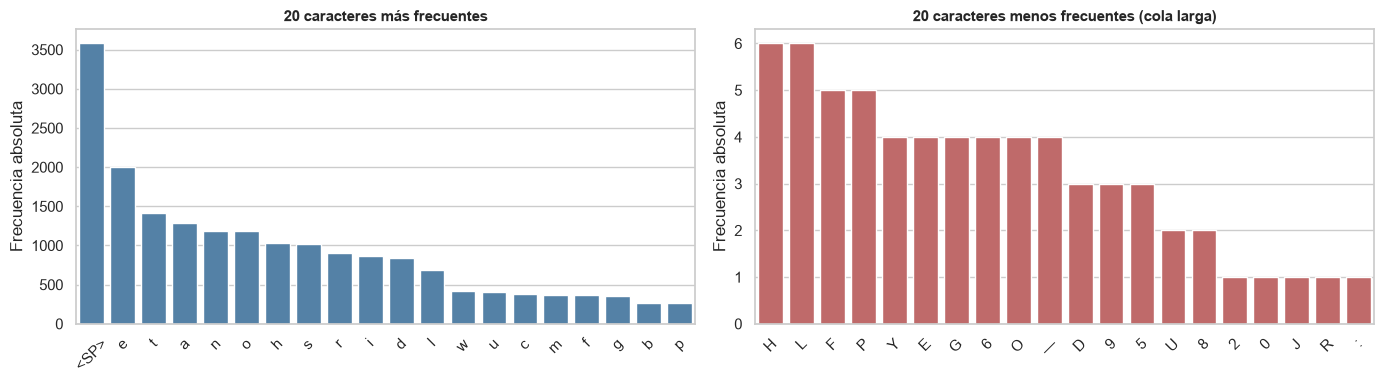

In [5]:
def vis(c):
    return {" ": "<SP>", "\n": "<NL>"}.get(str(c), str(c))

serie = pd.Series(char_counts).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

top20 = serie.head(20)
sns.barplot(x=[vis(c) for c in top20.index], y=top20.values, ax=axes[0], color="steelblue")
axes[0].set_title("20 caracteres más frecuentes", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Frecuencia absoluta")
axes[0].tick_params(axis="x", rotation=45)

bottom20 = serie.tail(20)
sns.barplot(x=[vis(c) for c in bottom20.index], y=bottom20.values, ax=axes[1], color="indianred")
axes[1].set_title("20 caracteres menos frecuentes (cola larga)", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Frecuencia absoluta")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


### Gráfico 2: Distribución de longitud de palabras

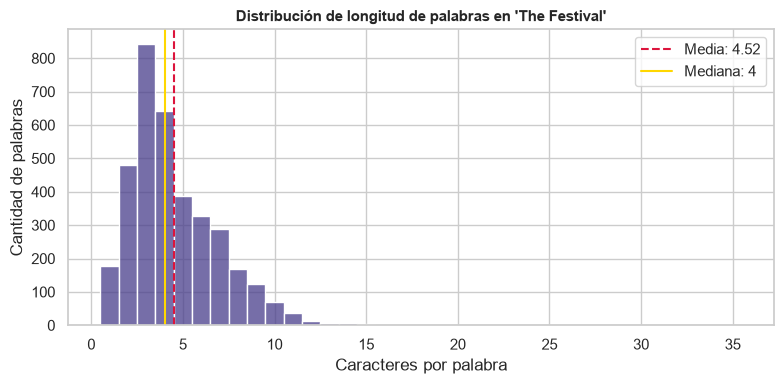

Palabras más largas del cuento: ['great-great-great-great-grandfather', 'winter-whitened', 'preternaturally', 'phosphorescence', 'church-crowned', 'spinning-wheel']


In [6]:
plt.figure(figsize=(8, 4))
sns.histplot(word_lengths, bins=range(1, word_lengths.max() + 2), discrete=True, color="darkslateblue")
plt.axvline(word_lengths.mean(), color="crimson", linestyle="--", label=f"Media: {word_lengths.mean():.2f}")
plt.axvline(np.median(word_lengths), color="gold", linestyle="-", label=f"Mediana: {np.median(word_lengths):.0f}")
plt.title("Distribución de longitud de palabras en 'The Festival'", fontsize=11, fontweight="bold")
plt.xlabel("Caracteres por palabra")
plt.ylabel("Cantidad de palabras")
plt.legend()
plt.tight_layout()
plt.show()

largas = sorted({w for w in words if len(w) >= 14}, key=len, reverse=True)
print("Palabras más largas del cuento:", largas[:6])


### Gráfico 3: Frecuencia de signos de puntuación

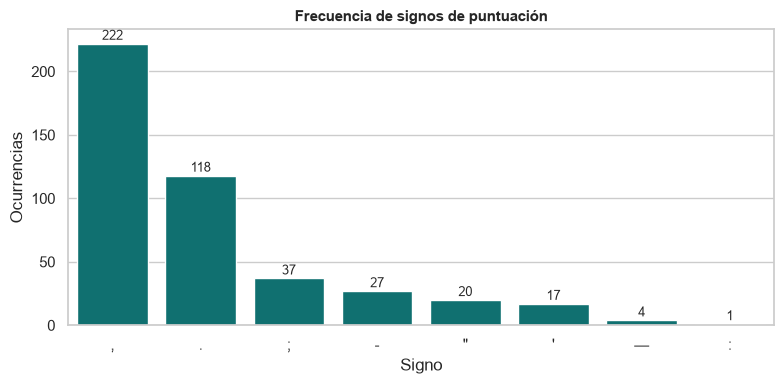

In [7]:
signos = set(".,;:!?'\"—-")
punct_counts = pd.Series([c for c in text if c in signos]).value_counts()

plt.figure(figsize=(8, 4))
sns.barplot(x=list(punct_counts.index), y=list(punct_counts.values), color="teal")
for i, n in enumerate(punct_counts.values):
    plt.text(i, n + 3, str(n), ha="center", fontsize=9)
plt.title("Frecuencia de signos de puntuación", fontsize=11, fontweight="bold")
plt.xlabel("Signo")
plt.ylabel("Ocurrencias")
plt.tight_layout()
plt.show()


### Diagnóstico de problemas potenciales: desbalance, outliers y estabilidad (data mismatch)

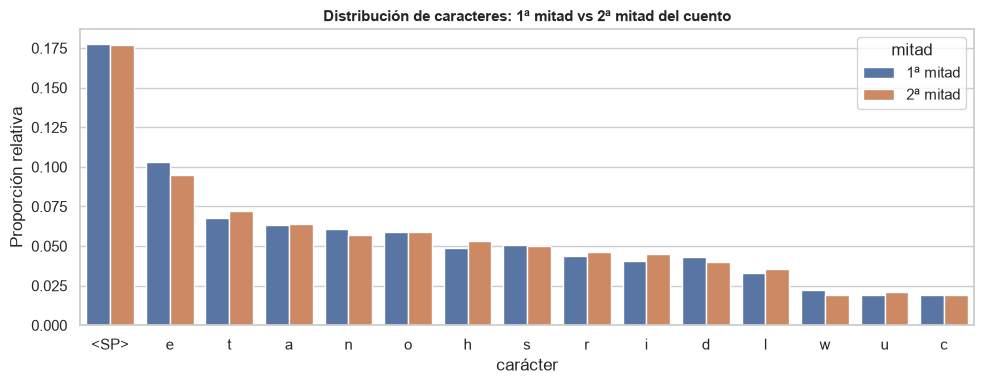

DIAGNÓSTICO DEL DATASET:
  • Desbalance: La clase mayoritaria '<SP>' representa el 17.7% del texto, mientras que ':' aparece solo 1 vez.
  • Outliers / Clases raras: 28 de 64 caracteres tienen menos de 10 apariciones: ['0', '1', '2', '5', '6', '8', '9', ':', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'R', 'U', 'W', 'Y', 'j', '—']
  • Estabilidad: Como muestra el gráfico comparativo, las frecuencias son sumamente estables entre mitades, descartando un data mismatch estilístico severo.


In [8]:
# Comparación de la 1ª mitad vs 2ª mitad del texto
mitad = len(text) // 2
c1, c2 = Counter(text[:mitad]), Counter(text[mitad:])
top15 = serie.index[:15]

df_mitades = pd.DataFrame({
    "carácter": [vis(c) for c in top15] * 2,
    "proporción": [c1[c] / mitad for c in top15] + [c2[c] / (len(text) - mitad) for c in top15],
    "mitad": ["1ª mitad"] * 15 + ["2ª mitad"] * 15
})

plt.figure(figsize=(10, 4))
sns.barplot(data=df_mitades, x="carácter", y="proporción", hue="mitad")
plt.title("Distribución de caracteres: 1ª mitad vs 2ª mitad del cuento", fontsize=11, fontweight="bold")
plt.ylabel("Proporción relativa")
plt.tight_layout()
plt.show()

raros = [c for c, n in char_counts.items() if n < 10]
print("DIAGNÓSTICO DEL DATASET:")
print(f"  • Desbalance: La clase mayoritaria '{vis(serie.index[0])}' representa el {serie.iloc[0]/len(text)*100:.1f}% del texto, mientras que '{vis(serie.index[-1])}' aparece solo {serie.iloc[-1]} vez.")
print(f"  • Outliers / Clases raras: {len(raros)} de {vocab_size} caracteres tienen menos de 10 apariciones: {sorted(vis(c) for c in raros)}")
print("  • Estabilidad: Como muestra el gráfico comparativo, las frecuencias son sumamente estables entre mitades, descartando un data mismatch estilístico severo.")


# 2. Consigna 4.1.2: Partición de datos (Train / Dev / Test)
## 2.1 Por qué partimos por bloques

In [9]:
# ==============================================================================
# PARTICIÓN POR BLOQUES CONTIGUOS (70% Train / 15% Dev / 15% Test)
# ==============================================================================
L = 40        # Longitud de la ventana de contexto
BLOQUE = 400  # Caracteres por bloque contiguo

limites = [(i, min(i + BLOQUE, len(text))) for i in range(0, len(text), BLOQUE)]
if limites[-1][1] - limites[-1][0] < BLOQUE // 2:
    ini_prev = limites[-2][0]
    limites = limites[:-2] + [(ini_prev, len(text))]

n_bloques = len(limites)
rng = np.random.default_rng(SEED)
orden = rng.permutation(n_bloques)

n_tr = round(0.70 * n_bloques)
n_dev = round(0.15 * n_bloques)

bloques_split = {
    "train": sorted(orden[:n_tr].tolist()),
    "dev":   sorted(orden[n_tr:n_tr + n_dev].tolist()),
    "test":  sorted(orden[n_tr + n_dev:].tolist()),
}

def ventanas_de_bloques(ids):
    X, y = [], []
    for b in ids:
        ini, fin = limites[b]
        for i in range(ini, fin - L):
            X.append(text[i:i+L])
            y.append(text[i+L])
    return X, y

X_train, y_train = ventanas_de_bloques(bloques_split["train"])
X_dev,   y_dev   = ventanas_de_bloques(bloques_split["dev"])
X_test,  y_test  = ventanas_de_bloques(bloques_split["test"])

n_total = len(X_train) + len(X_dev) + len(X_test)
print(f"Bloques totales: {n_bloques} (~{BLOQUE} caracteres c/u) -> Train: {len(bloques_split['train'])} | Dev: {len(bloques_split['dev'])} | Test: {len(bloques_split['test'])}")
print(f"  • Train: {len(X_train):>6,} muestras ({len(X_train)/n_total*100:4.1f}%)")
print(f"  • Dev:   {len(X_dev):>6,} muestras ({len(X_dev)/n_total*100:4.1f}%)")
print(f"  • Test:  {len(X_test):>6,} muestras ({len(X_test)/n_total*100:4.1f}%)")
print(f"\nEjemplo extraído:\n  Contexto X: {X_train[0]!r}\n  Objetivo y: {y_train[0]!r}")


Bloques totales: 50 (~400 caracteres c/u) -> Train: 35 | Dev: 8 | Test: 7
  • Train: 12,780 muestras (70.3%)
  • Dev:    2,880 muestras (15.8%)
  • Test:   2,520 muestras (13.9%)

Ejemplo extraído:
  Contexto X: 'e tongue of the blue-eyed fishers. And n'
  Objetivo y: 'o'


## 2.2 Verificación de la distribución de clases en los tres conjuntos

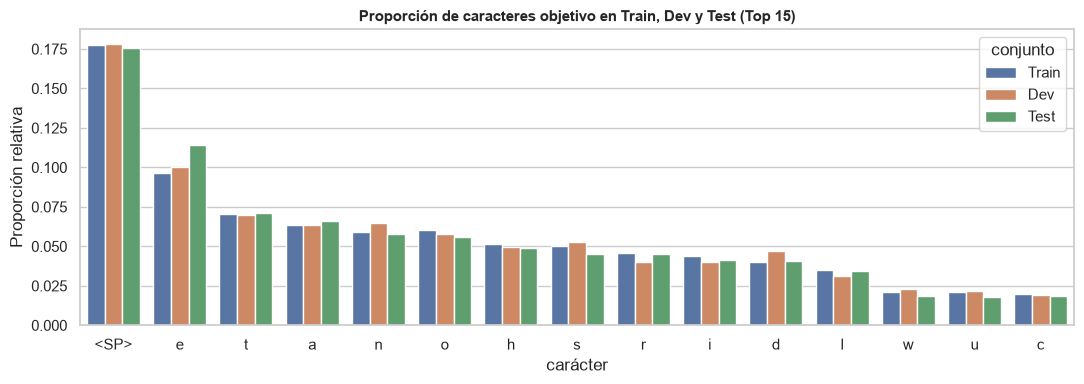

Caracteres en Dev/Test pero ausentes en Train: ['2']


In [10]:
conteos = {
    "Train": Counter(y_train),
    "Dev":   Counter(y_dev),
    "Test":  Counter(y_test),
}

freq = pd.DataFrame({s: pd.Series(c).reindex(vocabulary, fill_value=0) for s, c in conteos.items()})
prop = freq / freq.sum()

top15 = serie.index[:15]
df_p = prop.loc[top15].reset_index(names="carácter").melt(id_vars="carácter", var_name="conjunto", value_name="proporción")
df_p["carácter"] = df_p["carácter"].map(vis)

plt.figure(figsize=(11, 4))
sns.barplot(data=df_p, x="carácter", y="proporción", hue="conjunto")
plt.title("Proporción de caracteres objetivo en Train, Dev y Test (Top 15)", fontsize=11, fontweight="bold")
plt.ylabel("Proporción relativa")
plt.tight_layout()
plt.show()

sin_train = [vis(c) for c in vocabulary if freq.loc[c, "Train"] == 0 and (freq.loc[c, "Dev"] + freq.loc[c, "Test"]) > 0]
print(f"Caracteres en Dev/Test pero ausentes en Train: {sin_train}")


# 3. Consigna 4.1.3: Preprocesamiento y modelo baseline
## 3.1 Codificación numérica y persistencia de particiones

In [11]:
# ==============================================================================
# CODIFICACIÓN NUMÉRICA Y PERSISTENCIA
# ==============================================================================
char2idx = {c: i for i, c in enumerate(vocabulary)}
idx2char = {i: c for c, i in char2idx.items()}
V = len(vocabulary)

OUT_DIR = BASE_DIR / "data" / "processed"
OUT_DIR.mkdir(parents=True, exist_ok=True)

(OUT_DIR / "The_Festival_clean.txt").write_text(text, encoding="utf-8")
with open(OUT_DIR / "splits_bloques.json", "w", encoding="utf-8") as f:
    json.dump({
        "L": L,
        "BLOQUE": BLOQUE,
        "SEED": SEED,
        "limites_bloques": limites,
        "bloques": bloques_split,
        "vocabulario": "".join(vocabulary)
    }, f, ensure_ascii=False)

print(f"Vocabulario (|V| = {V}) y particiones guardados exitosamente en {OUT_DIR.relative_to(BASE_DIR)}/")


Vocabulario (|V| = 64) y particiones guardados exitosamente en data\processed/


## 3.2 Métrica de número único

In [12]:
# ==============================================================================
# REFERENCIA TRIVIAL: PREDICCIÓN DE LA CLASE MAYORITARIA
# ==============================================================================
clase_mayoritaria = serie.index[0]
acc_dummy_dev = np.mean([y == clase_mayoritaria for y in y_dev])

print(f"Clase mayoritaria en el texto: '{vis(clase_mayoritaria)}'")
print(f"Accuracy de referencia trivial en Dev: {acc_dummy_dev:.4f} ({acc_dummy_dev*100:.2f}%)")


Clase mayoritaria en el texto: '<SP>'
Accuracy de referencia trivial en Dev: 0.1785 (17.85%)


## 3.3 Baseline: regresión logística sobre los últimos $K$ caracteres

   Accuracy Train  Accuracy Dev  Tiempo (s)
K                                          
1          0.3005        0.3122      0.9691
3          0.4026        0.4069      1.3960
5          0.4297        0.4083      1.6859

Mejor K seleccionado con Dev: K = 5


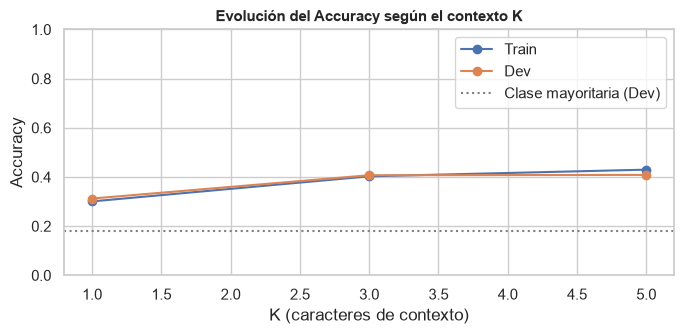

In [13]:
# ==============================================================================
# ENTRENAMIENTO DEL BASELINE CON VARIACIÓN DE CONTEXTO K
# ==============================================================================
def ultimos(X, k):
    return np.array([list(x[-k:]) for x in X])

resultados_k = []
modelos_k = {}
tiempos_k = {}

for k in [1, 3, 5]:
    pipe = Pipeline([
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ("clf", LogisticRegression(max_iter=500, random_state=SEED)),
    ])
    t0 = time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        pipe.fit(ultimos(X_train, k), y_train)
    tiempos_k[k] = time.perf_counter() - t0
    
    modelos_k[k] = pipe
    acc_tr = accuracy_score(y_train, pipe.predict(ultimos(X_train, k)))
    acc_dev = accuracy_score(y_dev, pipe.predict(ultimos(X_dev, k)))
    resultados_k.append({"K": k, "Accuracy Train": acc_tr, "Accuracy Dev": acc_dev, "Tiempo (s)": tiempos_k[k]})

df_k = pd.DataFrame(resultados_k).set_index("K")
print(df_k.round(4))

K_OPTIMO = int(df_k["Accuracy Dev"].idxmax())
print(f"\nMejor K seleccionado con Dev: K = {K_OPTIMO}")

plt.figure(figsize=(7, 3.5))
plt.plot(df_k.index, df_k["Accuracy Train"], marker="o", label="Train")
plt.plot(df_k.index, df_k["Accuracy Dev"], marker="o", label="Dev")
plt.axhline(acc_dummy_dev, color="gray", linestyle=":", label="Clase mayoritaria (Dev)")
plt.xlabel("K (caracteres de contexto)")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.title("Evolución del Accuracy según el contexto K", fontsize=11, fontweight="bold")
plt.legend()
plt.tight_layout()
plt.show()

## 3.4 Resultado del baseline en Dev

In [14]:
# ==============================================================================
# REPORTE OFICIAL DEL BASELINE EN DEV (Consigna 4.1.3)
# ==============================================================================
baseline_final = modelos_k[K_OPTIMO]
Xdev_opt = ultimos(X_dev, K_OPTIMO)
y_pred_dev = baseline_final.predict(Xdev_opt)

acc_base_dev = accuracy_score(y_dev, y_pred_dev)

# Métricas complementarias, medidas aquí para no fijarlas a mano en etapas posteriores
acc_base_train = accuracy_score(y_train, baseline_final.predict(ultimos(X_train, K_OPTIMO)))

def perdida_log(pipe, X_k, y_real):
    """Entropía cruzada media. Si un carácter real no está entre las clases del modelo, recibe probabilidad 1e-15."""
    proba = pipe.predict_proba(X_k)
    col = {c: j for j, c in enumerate(pipe.classes_)}
    p_real = np.array([proba[i, col[c]] if c in col else 1e-15 for i, c in enumerate(y_real)])
    return float(-np.mean(np.log(np.clip(p_real, 1e-15, 1.0))))

loss_base_dev = perdida_log(baseline_final, Xdev_opt, y_dev)
perp_base_dev = float(np.exp(loss_base_dev))
clf_base = baseline_final.named_steps["clf"]
params_base = int(clf_base.coef_.size + clf_base.intercept_.size)
tiempo_base = tiempos_k[K_OPTIMO]

print("=" * 70)
print(f"BASELINE OFICIAL — One-Hot últimos {K_OPTIMO} caracteres + Regresión Logística:")
print(f"  • Accuracy en Dev: {acc_base_dev:.4f} ({acc_base_dev*100:.2f}%)")
print(f"  • Referencia trivial (clase mayoritaria): {acc_dummy_dev:.4f} ({acc_dummy_dev*100:.2f}%)")
print(f"  • Ganancia sobre la referencia trivial: +{(acc_base_dev - acc_dummy_dev)*100:.2f} puntos porcentuales")
print(f"  • Muestras evaluadas en Dev: {len(y_dev)}")
print(f"  • Accuracy en Train: {acc_base_train*100:.2f}% (brecha Train - Dev: {(acc_base_train - acc_base_dev)*100:.2f} pp)")
print(f"  • Pérdida (entropía cruzada) en Dev: {loss_base_dev:.4f} | Perplejidad en Dev: {perp_base_dev:.2f}")
print(f"  • Parámetros entrenables: {params_base:,} | Tiempo de entrenamiento: {tiempo_base:.2f} s")
print("=" * 70)

# Guardar en disco para referencia futura en Etapa 2 y 5
with open(OUT_DIR / "baseline_dev.json", "w", encoding="utf-8") as f:
    json.dump({
        "modelo": f"OneHot_ultimos_{K_OPTIMO}_chars + LogisticRegression",
        "K": K_OPTIMO,
        "metrica_principal": "accuracy_dev",
        "accuracy_dev": float(acc_base_dev),
        "accuracy_train": float(acc_base_train),
        "loss_dev": loss_base_dev,
        "perplejidad_dev": perp_base_dev,
        "parametros_entrenables": params_base,
        "tiempo_entrenamiento_s": tiempo_base,
        "accuracy_dummy_dev": float(acc_dummy_dev),
        "n_dev": len(y_dev)
    }, f, indent=2)
print("Métrica oficial guardada en data/processed/baseline_dev.json")


BASELINE OFICIAL — One-Hot últimos 5 caracteres + Regresión Logística:
  • Accuracy en Dev: 0.4083 (40.83%)
  • Referencia trivial (clase mayoritaria): 0.1785 (17.85%)
  • Ganancia sobre la referencia trivial: +22.99 puntos porcentuales
  • Muestras evaluadas en Dev: 2880
  • Accuracy en Train: 42.97% (brecha Train - Dev: 2.13 pp)
  • Pérdida (entropía cruzada) en Dev: 2.0853 | Perplejidad en Dev: 8.05
  • Parámetros entrenables: 19,908 | Tiempo de entrenamiento: 1.69 s
Métrica oficial guardada en data/processed/baseline_dev.json


## 3.5 Matriz de confusión del baseline

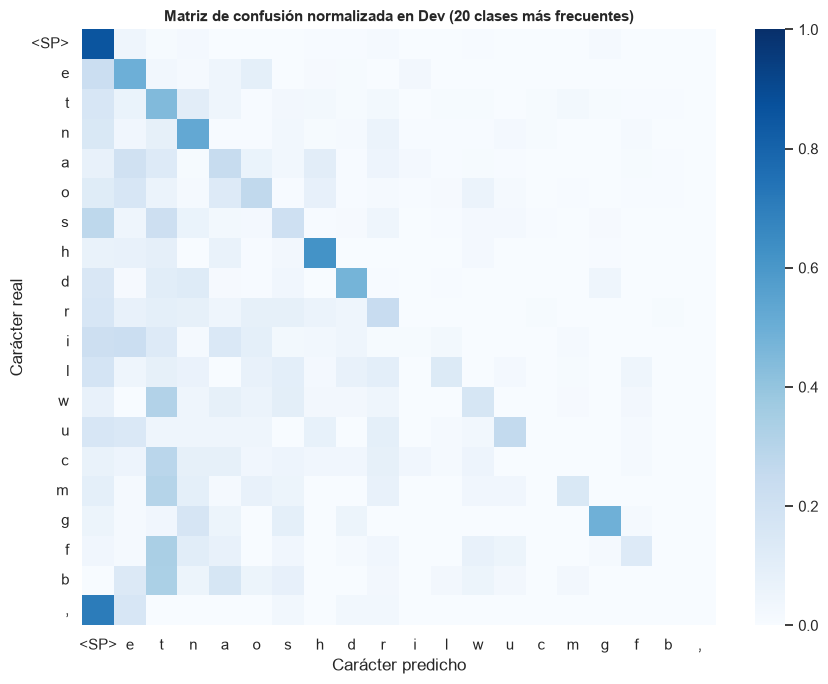

Total de errores en Dev: 1704 de 2880

Pares de caracteres más confundidos (real -> predicho):
Real Predicho  Ocurrencias
   e     <SP>           65
   s     <SP>           42
   a        e           37
   t     <SP>           33
   s        t           33
   n     <SP>           28
   e        o           28
   o        e           27


In [15]:
# ==============================================================================
# MATRIZ DE CONFUSIÓN Y ANÁLISIS DE ERRORES EN DEV
# ==============================================================================
labels_all = sorted(set(y_dev) | set(y_pred_dev))
cm = confusion_matrix(y_dev, y_pred_dev, labels=labels_all, normalize="true")

top20 = [c for c, _ in Counter(y_dev).most_common(20)]
ix = [labels_all.index(c) for c in top20]

plt.figure(figsize=(9, 7))
sns.heatmap(cm[np.ix_(ix, ix)], cmap="Blues", vmin=0, vmax=1,
            xticklabels=[vis(c) for c in top20], yticklabels=[vis(c) for c in top20])
plt.title("Matriz de confusión normalizada en Dev (20 clases más frecuentes)", fontsize=11, fontweight="bold")
plt.xlabel("Carácter predicho")
plt.ylabel("Carácter real")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

errores = [(r, p) for r, p in zip(y_dev, y_pred_dev) if r != p]
top_errores = Counter(errores).most_common(8)
print(f"Total de errores en Dev: {len(errores)} de {len(y_dev)}")
print("\nPares de caracteres más confundidos (real -> predicho):")
df_err = pd.DataFrame([(vis(r), vis(p), n) for (r, p), n in top_errores], columns=["Real", "Predicho", "Ocurrencias"])
print(df_err.to_string(index=False))


# 4. Síntesis y checklist de la Etapa 1

In [16]:
print("CHECKLIST DE CUMPLIMIENTO - ETAPA 1")
print(f"  [x] 4.1.1 Carga y EDA: {len(text):,} caracteres, |V| = {vocab_size}, 3 gráficos descriptivos y diagnóstico de problemas.")
print(f"  [x] 4.1.2 Partición: Train ({len(X_train):,}) / Dev ({len(X_dev):,}) / Test ({len(X_test):,}) mediante bloques contiguos sin data leakage.")
print("  [x] 4.1.2 Proporción de clases verificada en los tres conjuntos.")
print(f"  [x] 4.1.3 Preprocesamiento y Baseline: One-Hot de últimos {K_OPTIMO} caracteres + Regresión Logística multinomial.")
print(f"  [x] 4.1.3 Métrica de número único: Accuracy en Dev = {acc_base_dev:.4f} (referencia trivial = {acc_dummy_dev:.4f}).")
print("  [x] Particiones, vocabulario y baseline guardados en data/processed/ para la Etapa 2.")
print("  [x] Conjunto Test preservado estrictamente intacto para la evaluación final en la Etapa 5.")


CHECKLIST DE CUMPLIMIENTO - ETAPA 1
  [x] 4.1.1 Carga y EDA: 20,180 caracteres, |V| = 64, 3 gráficos descriptivos y diagnóstico de problemas.
  [x] 4.1.2 Partición: Train (12,780) / Dev (2,880) / Test (2,520) mediante bloques contiguos sin data leakage.
  [x] 4.1.2 Proporción de clases verificada en los tres conjuntos.
  [x] 4.1.3 Preprocesamiento y Baseline: One-Hot de últimos 5 caracteres + Regresión Logística multinomial.
  [x] 4.1.3 Métrica de número único: Accuracy en Dev = 0.4083 (referencia trivial = 0.1785).
  [x] Particiones, vocabulario y baseline guardados en data/processed/ para la Etapa 2.
  [x] Conjunto Test preservado estrictamente intacto para la evaluación final en la Etapa 5.


# 5. Etapa 2: Red neuronal multicapa (MLP) y regularización
### Decisiones de la Etapa 2

In [17]:
# ==============================================================================
# 5.1 CONFIGURACIÓN DE TENSORFLOW/KERAS Y PREPARACIÓN DE TENSORES
# ==============================================================================
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # Ocultar mensajes de bajo nivel de C++
os.environ["KERAS_HOME"] = os.path.abspath(os.path.join(os.getcwd(), "..", "..", ".keras"))

import time
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks

print(f"TensorFlow Version: {tf.__version__}")
print(f"Keras Version:      {keras.__version__}")

# Semillas fijas para la evaluación multi-semilla
SEEDS = [42, 123, 456, 789, 2026]

# ------------------------------------------------------------------------------
# Transformación a tensores densos One-Hot aplanados (N, K * |V|) = (N, 320)
# Cada posición se codifica en un vector binario de dimensión |V| = 64
# ------------------------------------------------------------------------------
def extraer_tensores_onehot(X_raw, y_raw, k, c2i, v_size):
    N = len(X_raw)
    X_oh = np.zeros((N, k * v_size), dtype=np.float32)
    y_idx = np.array([c2i[c] for c in y_raw], dtype=np.int32)
    
    for i, seq in enumerate(X_raw):
        ctx_k = seq[-k:]
        for pos, char in enumerate(ctx_k):
            c_idx = c2i[char]
            X_oh[i, pos * v_size + c_idx] = 1.0
            
    return X_oh, y_idx

X_train_oh, y_train_idx = extraer_tensores_onehot(X_train, y_train, K_OPTIMO, char2idx, vocab_size)
X_dev_oh, y_dev_idx     = extraer_tensores_onehot(X_dev, y_dev, K_OPTIMO, char2idx, vocab_size)

print("\nDimensiones de los tensores generados para Keras:")
print(f"  • X_train_oh: {X_train_oh.shape}  | y_train_idx: {y_train_idx.shape}")
print(f"  • X_dev_oh:   {X_dev_oh.shape}   | y_dev_idx:   {y_dev_idx.shape}")
print(f"  • Features por muestra: {X_train_oh.shape[1]} ({K_OPTIMO} caracteres * {vocab_size} clases)")


TensorFlow Version: 2.21.0
Keras Version:      3.15.1

Dimensiones de los tensores generados para Keras:
  • X_train_oh: (12780, 320)  | y_train_idx: (12780,)
  • X_dev_oh:   (2880, 320)   | y_dev_idx:   (2880,)
  • Features por muestra: 320 (5 caracteres * 64 clases)


# 6. Consigna 4.2.1: Análisis manual de errores del baseline
### Reglas para asignar la causa (en orden de precedencia)

Total de errores del baseline en Dev: 1704 de 2880 (Tasa de error = 59.17%)


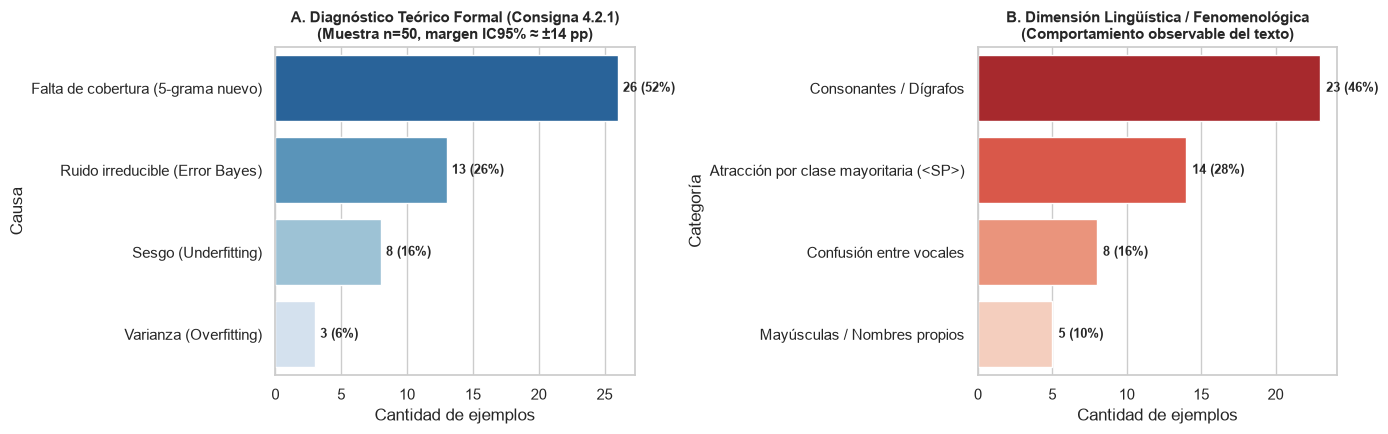

,Contexto (5 chars),Target Real,Pred. Baseline,Causa Teórica (ML),Categoría Lingüística
1046,g. Af,t,<SP>,Falta de cobertura (5-grama nuevo),Atracción por clase mayoritaria (<SP>)
745,and,a,t,Ruido irreducible (Error Bayes),Consonantes / Dígrafos
785,ied.,H,T,Falta de cobertura (5-grama nuevo),Mayúsculas / Nombres propios
367,old,P,m,Ruido irreducible (Error Bayes),Mayúsculas / Nombres propios
1029,e age,d,<SP>,Falta de cobertura (5-grama nuevo),Atracción por clase mayoritaria (<SP>)
1648,a na,s,t,Sesgo (Underfitting),Consonantes / Dígrafos
259,"692,",b,t,Falta de cobertura (5-grama nuevo),Consonantes / Dígrafos
1509,e I c,o,a,Sesgo (Underfitting),Confusión entre vocales
514,in m,e,a,Falta de cobertura (5-grama nuevo),Confusión entre vocales
1229,that,c,<SP>,Ruido irreducible (Error Bayes),Atracción por clase mayoritaria (<SP>)


In [18]:
# ==============================================================================
# 6.1 ANÁLISIS DE ERRORES DETERMINÍSTICO Y MUESTREO DE 50 CASOS (Consigna 4.2.1)
# ==============================================================================
# Predicciones del Baseline K=5 en Train y Dev
best_pipe = modelos_k[K_OPTIMO]
y_pred_tr_base  = best_pipe.predict(ultimos(X_train, K_OPTIMO))
y_pred_dev_base = best_pipe.predict(ultimos(X_dev, K_OPTIMO))

ctx_train_k = ["".join(x) for x in ultimos(X_train, K_OPTIMO)]
ctx_dev_k   = ["".join(x) for x in ultimos(X_dev, K_OPTIMO)]

from collections import defaultdict
ctx_train_stats = defaultdict(list)
for ctx, yr, yp in zip(ctx_train_k, y_train, y_pred_tr_base):
    ctx_train_stats[ctx].append((yr, yp))

# Filtrar todos los errores en Dev
errores_dev = []
for idx, (ctx, yr, yp) in enumerate(zip(ctx_dev_k, y_dev, y_pred_dev_base)):
    if yr != yp:
        errores_dev.append({
            "dev_idx": idx,
            "contexto": ctx,
            "y_real": yr,
            "y_pred": yp
        })

print(f"Total de errores del baseline en Dev: {len(errores_dev)} de {len(y_dev)} (Tasa de error = {len(errores_dev)/len(y_dev)*100:.2f}%)")

# Funciones de clasificación con orden de precedencia documentado
def clasificar_causa_teorica(ctx, yr, yp):
    if ctx not in ctx_train_stats:
        return "Falta de cobertura (5-grama nuevo)"
    ocurr = ctx_train_stats[ctx]
    targets = [t[0] for t in ocurr]
    conteo = Counter(targets)
    moda = conteo.most_common(1)[0][0]
    if len(conteo) > 1 and yr != moda:
        return "Ruido irreducible (Error Bayes)"
    aciertos = sum(1 for t, p in ocurr if t == p)
    if (aciertos / len(ocurr)) <= 0.5:
        return "Sesgo (Underfitting)"
    return "Varianza (Overfitting)"

def clasificar_fenomeno_linguistico(yr, yp):
    if yp == ' ':
        return "Atracción por clase mayoritaria (<SP>)"
    if yr == ' ':
        return "Fin de palabra no detectado (omisión <SP>)"
    if yr.lower() in "aeiou" and yp.lower() in "aeiou":
        return "Confusión entre vocales"
    if yr.isupper() or yp.isupper():
        return "Mayúsculas / Nombres propios"
    if yr in ".-,;:!?'\"—" or yp in ".-,;:!?'\"—":
        return "Puntuación / Delimitadores"
    return "Consonantes / Dígrafos"

for e in errores_dev:
    e["causa_teorica"] = clasificar_causa_teorica(e["contexto"], e["y_real"], e["y_pred"])
    e["categoria_ling"] = clasificar_fenomeno_linguistico(e["y_real"], e["y_pred"])

df_errores_all = pd.DataFrame(errores_dev)

# Muestra aleatoria de 50 errores con semilla fija
df_50_muestra = df_errores_all.sample(n=50, random_state=SEED).copy()
ruta_50 = os.path.join("..", "data", "processed", "muestra_50_errores_dev.csv")
# Conservamos la revisión manual del grupo (columna causa_manual) si el archivo ya existe
df_50_muestra["causa_manual"] = ""
if os.path.exists(ruta_50):
    previo = pd.read_csv(ruta_50, encoding="utf-8", dtype={"causa_manual": str})
    if "causa_manual" in previo.columns:
        df_50_muestra["causa_manual"] = df_50_muestra["dev_idx"].map(previo.set_index("dev_idx")["causa_manual"]).fillna("")
df_50_muestra.to_csv(ruta_50, index=False, encoding="utf-8")

# Visualización de los 50 errores clasificados
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

causas_cnt = df_50_muestra["causa_teorica"].value_counts().reset_index()
causas_cnt.columns = ["Causa", "Casos"]
sns.barplot(data=causas_cnt, x="Casos", y="Causa", hue="Causa", legend=False, ax=axes[0], palette="Blues_r")
axes[0].set_title("A. Diagnóstico Teórico Formal (Consigna 4.2.1)\n(Muestra n=50, margen IC95% ≈ ±14 pp)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Cantidad de ejemplos")
for i, v in enumerate(causas_cnt["Casos"]):
    axes[0].text(v + 0.4, i, f"{v} ({v*2}%)", va="center", fontsize=9, fontweight="bold")

ling_cnt = df_50_muestra["categoria_ling"].value_counts().reset_index()
ling_cnt.columns = ["Categoría", "Casos"]
sns.barplot(data=ling_cnt, x="Casos", y="Categoría", hue="Categoría", legend=False, ax=axes[1], palette="Reds_r")
axes[1].set_title("B. Dimensión Lingüística / Fenomenológica\n(Comportamiento observable del texto)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Cantidad de ejemplos")
for i, v in enumerate(ling_cnt["Casos"]):
    axes[1].text(v + 0.4, i, f"{v} ({v*2}%)", va="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()

# Mostrar primeros 10 casos en tabla formateada
def vis_c(c): return "<SP>" if c == " " else str(c)
df_disp = df_50_muestra[["contexto", "y_real", "y_pred", "causa_teorica", "categoria_ling"]].head(10).copy()
df_disp["y_real"] = df_disp["y_real"].map(vis_c)
df_disp["y_pred"] = df_disp["y_pred"].map(vis_c)
df_disp.columns = ["Contexto (5 chars)", "Target Real", "Pred. Baseline", "Causa Teórica (ML)", "Categoría Lingüística"]
df_disp


### 6.1.1 Qué muestran los 50 errores

### 6.2 Diagnóstico de sesgo y varianza del baseline

### 6.3 Accuracy por tipo de carácter

In [19]:
# ==============================================================================
# 6.3 ACCURACY POR TIPO DE CARÁCTER EN DEV
# ==============================================================================
TIPOS_CHAR = ["espacio", "vocal", "consonante", "mayúscula", "puntuación/dígito"]

def tipo_caracter(c):
    if c == " ":
        return "espacio"
    if c.isupper():
        return "mayúscula"
    if c in "aeiou":
        return "vocal"
    if c.isalpha():
        return "consonante"
    return "puntuación/dígito"

tipos_dev = np.array([tipo_caracter(c) for c in y_dev])

def accuracy_por_tipo(y_pred, y_real=y_dev, tipos=tipos_dev):
    """Accuracy separada por tipo de carácter real, más la accuracy global."""
    y_pred, y_real = np.asarray(y_pred), np.asarray(y_real)
    res = {t: (y_pred[tipos == t] == y_real[tipos == t]).mean() for t in TIPOS_CHAR}
    res["global"] = (y_pred == y_real).mean()
    return res

soporte_tipos = pd.Series(tipos_dev).value_counts().reindex(TIPOS_CHAR)
df_tipos_base = pd.DataFrame({
    "Casos en Dev": soporte_tipos,
    "% de Dev": (soporte_tipos / len(y_dev) * 100).round(1),
    "Accuracy Baseline": pd.Series(accuracy_por_tipo(y_pred_dev_base)).reindex(TIPOS_CHAR).round(4),
})
df_tipos_base


,Casos en Dev,% de Dev,Accuracy Baseline
espacio,514,17.8,0.8580
vocal,817,28.4,0.3060
consonante,1451,50.4,0.3280
mayúscula,38,1.3,0.1842
puntuación/dígito,60,2.1,0.0333


### 6.4 Explicación de predicciones individuales

In [20]:
# ==============================================================================
# 6.4 EXPLICACIÓN DE PREDICCIONES
# ==============================================================================
def proba_baseline(contextos):
    """Matriz (n, |V|) de probabilidades del baseline, en el orden de char2idx."""
    proba = best_pipe.predict_proba(ultimos(contextos, K_OPTIMO))
    salida = np.zeros((len(contextos), vocab_size))
    for j, c in enumerate(best_pipe.classes_):
        salida[:, char2idx[c]] = proba[:, j]
    return salida

def explicar_prediccion(proba_fn, contexto, y_real, nombre_modelo, top=5):
    """Imprime el top de caracteres más probables y el puesto que ocupa el carácter real."""
    p = proba_fn([contexto])[0]
    orden = np.argsort(p)[::-1]
    puesto_real = int(np.where(orden == char2idx[y_real])[0][0]) + 1
    print(f"  [{nombre_modelo}] contexto '...{contexto[-20:]}' | real '{vis_c(y_real)}' "
          f"en el puesto {puesto_real} (P = {p[char2idx[y_real]]:.3f})")
    print("     top-" + str(top) + ": " + " | ".join(f"'{vis_c(idx2char[j])}' {p[j]:.3f}" for j in orden[:top]))

# Un caso de cada causa (pre-etiqueta por reglas) de la muestra de 50 errores
casos_ejemplo = df_50_muestra.groupby("causa_teorica", sort=False).head(1)
for _, fila in casos_ejemplo.iterrows():
    print(f"Causa (pre-etiqueta por reglas): {fila['causa_teorica']}")
    explicar_prediccion(proba_baseline, X_dev[fila["dev_idx"]], fila["y_real"], "Baseline")
    print()


Causa (pre-etiqueta por reglas): Falta de cobertura (5-grama nuevo)
  [Baseline] contexto '...ad been striking. Af' | real 't' en el puesto 4 (P = 0.074)
     top-5: '<SP>' 0.503 | 'a' 0.102 | 'o' 0.100 | 't' 0.074 | 'l' 0.048

Causa (pre-etiqueta por reglas): Ruido irreducible (Error Bayes)
  [Baseline] contexto '... wrote a quaint and ' | real 'a' en el puesto 4 (P = 0.090)
     top-5: 't' 0.147 | 'w' 0.140 | 's' 0.095 | 'a' 0.090 | 'h' 0.059

Causa (pre-etiqueta por reglas): Sesgo (Underfitting)
  [Baseline] contexto '...tone above with a na' | real 's' en el puesto 3 (P = 0.088)
     top-5: 't' 0.160 | 'd' 0.127 | 's' 0.088 | 'l' 0.087 | '<SP>' 0.086

Causa (pre-etiqueta por reglas): Varianza (Overfitting)
  [Baseline] contexto '...ersons on the settle' | real ',' en el puesto 3 (P = 0.054)
     top-5: '<SP>' 0.708 | 'n' 0.055 | ',' 0.054 | 's' 0.045 | 'e' 0.019



# 7. Consigna 4.2.2: Arquitectura MLP
### Arquitectura
### Parámetros entrenables

In [21]:
# ==============================================================================
# 7. CONSTRUCCIÓN Y ENTRENAMIENTO DEL MLP
# ==============================================================================
EPOCAS = 100
BATCH = 128

def construir_mlp(k=5, v_size=64, dropout_rate=0.0, l2_reg=0.0, batchnorm=False):
    """
    Construye una red neuronal densa (MLP) de 3 capas ocultas con tf.keras.
    Permite activar Dropout, regularización L2 y Batch Normalization para la sección 8.
    """
    reg = regularizers.l2(l2_reg) if l2_reg > 0 else None

    capas = [layers.Input(shape=(k * v_size,))]
    for units in [128, 64, 32]:
        if batchnorm:
            # Batch Normalization entre la capa densa y su activación
            capas += [layers.Dense(units, kernel_regularizer=reg), layers.BatchNormalization(), layers.Activation("relu")]
        else:
            capas.append(layers.Dense(units, activation="relu", kernel_regularizer=reg))
        if dropout_rate > 0.0:
            capas.append(layers.Dropout(dropout_rate))

    capas.append(layers.Dense(v_size, activation="softmax", kernel_regularizer=reg))
    return keras.Sequential(capas)

def entrenar_mlp(seed, lr, dropout=0.0, l2=0.0, batchnorm=False, use_es=False, patience=0, plateau=None, epochs=EPOCAS):
    """Entrena un MLP con la configuración dada y devuelve (modelo, historial, tiempo en segundos)."""
    keras.utils.set_random_seed(seed)
    modelo = construir_mlp(k=K_OPTIMO, v_size=vocab_size, dropout_rate=dropout, l2_reg=l2, batchnorm=batchnorm)
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    cbs = []
    if plateau:
        # Baja el learning rate cuando la pérdida en Dev se estanca
        cbs.append(callbacks.ReduceLROnPlateau(monitor="val_loss", **plateau))
    if use_es:
        cbs.append(callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True))
    t0 = time.perf_counter()
    h = modelo.fit(X_train_oh, y_train_idx, validation_data=(X_dev_oh, y_dev_idx),
                   epochs=epochs, batch_size=BATCH, callbacks=cbs, verbose=0)
    return modelo, h, time.perf_counter() - t0

def evaluar_config(cfg):
    """Entrena una configuración con las 5 semillas y devuelve (resumen, historial y modelo de la semilla 42)."""
    corridas = []
    for s in SEEDS:
        modelo, h, t_run = entrenar_mlp(s, **cfg)
        if s == SEED:
            h42, m42 = h.history, modelo

        loss_tr, acc_tr   = [float(v) for v in modelo.evaluate(X_train_oh, y_train_idx, verbose=0)]
        loss_dev, acc_dev = [float(v) for v in modelo.evaluate(X_dev_oh, y_dev_idx, verbose=0)]
        va, vl = h.history["val_accuracy"], h.history["val_loss"]

        corridas.append({
            "seed": s, "tiempo": t_run, "epocas": len(h.history["loss"]),
            "train_acc": acc_tr, "dev_acc": acc_dev, "brecha": acc_tr - acc_dev,
            "train_loss": loss_tr, "dev_loss": loss_dev, "dev_perp": float(np.exp(loss_dev)),
            # Época (1-indexada) del pico de accuracy y del mínimo de pérdida en Dev
            "pico_acc": float(max(va)), "ep_pico_acc": int(np.argmax(va)) + 1,
            "min_loss": float(min(vl)), "ep_min_loss": int(np.argmin(vl)) + 1,
            "acc_en_min_loss": float(va[int(np.argmin(vl))]),
        })
        corridas[-1]["distancia"] = corridas[-1]["ep_pico_acc"] - corridas[-1]["ep_min_loss"]

    df_c = pd.DataFrame(corridas)
    resumen = {"config": cfg, "params": int(m42.count_params()), "dev_acc_min": float(df_c["dev_acc"].min())}
    for col in df_c.columns.drop("seed"):
        resumen[f"{col}_mean"] = float(df_c[col].mean())
        resumen[f"{col}_std"] = float(df_c[col].std())
    resumen["corridas"] = corridas
    return resumen, h42, m42

# Verificación de la arquitectura sin regularización
keras.utils.set_random_seed(SEED)
mlp_demo = construir_mlp(k=K_OPTIMO, v_size=vocab_size)
print(f"Parámetros verificados del MLP: {mlp_demo.count_params():,}")
mlp_demo.summary()

Parámetros verificados del MLP: 53,536


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,536 (209.12 KB)

 Trainable params: 53,536 (209.12 KB)

 Non-trainable params: 0 (0.00 B)

### 7.1 Ajuste del learning rate

  lr = 0.001 listo (23.4 s por corrida)


  lr = 0.0005 listo (23.3 s por corrida)


  lr = 0.0001 listo (23.1 s por corrida)


  lr = 5e-05 listo (23.4 s por corrida)


,Pico acc Dev (μ ± σ),Época del pico,Época mín. val_loss,Distancia (épocas),Mín. val_loss,Acc Dev época 100,Brecha época 100
lr,,,,,,,
0.001,47.26% ± 0.34%,37.0,13.8,23.2,1.9199,45.64%,31.07 pp
0.0005,47.56% ± 0.42%,63.8,26.4,37.4,1.9200,46.90%,24.17 pp
0.0001,44.88% ± 0.47%,98.8,100.0,-1.2,1.9375,44.84%,6.36 pp
5e-05,41.76% ± 0.47%,99.4,100.0,-0.6,2.0477,41.76%,2.14 pp



Learning rate elegido: 0.0005  |  ¿En el borde del rango probado? False


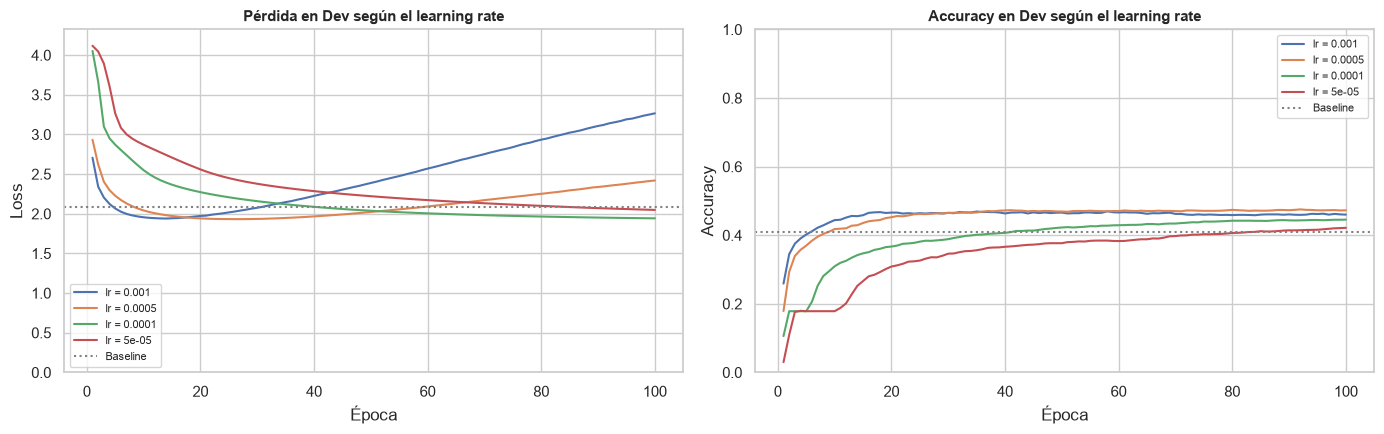

In [22]:
# ==============================================================================
# 7.1 AJUSTE DEL LEARNING RATE (MLP sin regularizar, 5 semillas, 100 épocas)
# ==============================================================================
LRS = [1e-3, 5e-4, 1e-4, 5e-5]
resultados_lr, historiales_lr, modelos_lr = {}, {}, {}

for lr in LRS:
    resultados_lr[lr], historiales_lr[lr], modelos_lr[lr] = evaluar_config({"lr": lr})
    print(f"  lr = {lr:g} listo ({resultados_lr[lr]['tiempo_mean']:.1f} s por corrida)")

df_lr = pd.DataFrame([{
    "lr": f"{lr:g}",
    "Pico acc Dev (μ ± σ)": f"{r['pico_acc_mean']*100:.2f}% ± {r['pico_acc_std']*100:.2f}%",
    "Época del pico": f"{r['ep_pico_acc_mean']:.1f}",
    "Época mín. val_loss": f"{r['ep_min_loss_mean']:.1f}",
    "Distancia (épocas)": f"{r['distancia_mean']:.1f}",
    "Mín. val_loss": f"{r['min_loss_mean']:.4f}",
    "Acc Dev época 100": f"{r['dev_acc_mean']*100:.2f}%",
    "Brecha época 100": f"{r['brecha_mean']*100:.2f} pp",
} for lr, r in resultados_lr.items()]).set_index("lr")
display(df_lr)

# Criterio declarado: mayor pico medio de accuracy en Dev
LR_OPT = max(LRS, key=lambda lr: resultados_lr[lr]["pico_acc_mean"])
print(f"\nLearning rate elegido: {LR_OPT:g}  |  ¿En el borde del rango probado? {LR_OPT in (min(LRS), max(LRS))}")

# Curvas de validación por learning rate (semilla 42)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for lr in LRS:
    h = historiales_lr[lr]
    ep = range(1, len(h["loss"]) + 1)
    axes[0].plot(ep, h["val_loss"], label=f"lr = {lr:g}")
    axes[1].plot(ep, h["val_accuracy"], label=f"lr = {lr:g}")
axes[0].axhline(loss_base_dev, color="gray", linestyle=":", label="Baseline")
axes[1].axhline(acc_base_dev, color="gray", linestyle=":", label="Baseline")
axes[0].set_ylim(0, max(max(h["val_loss"]) for h in historiales_lr.values()) * 1.05)
axes[1].set_ylim(0, 1)
axes[0].set_title("Pérdida en Dev según el learning rate", fontsize=11, fontweight="bold")
axes[1].set_title("Accuracy en Dev según el learning rate", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Loss")
axes[1].set_ylabel("Accuracy")
for ax in axes:
    ax.set_xlabel("Época")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

MLP sin regularizar, lr = 0.0005, 100 épocas (5 semillas):
  • Accuracy Train: 71.07% ± 0.64%
  • Accuracy Dev:   46.90% ± 0.49%
  • Brecha Train - Dev: 24.17 pp


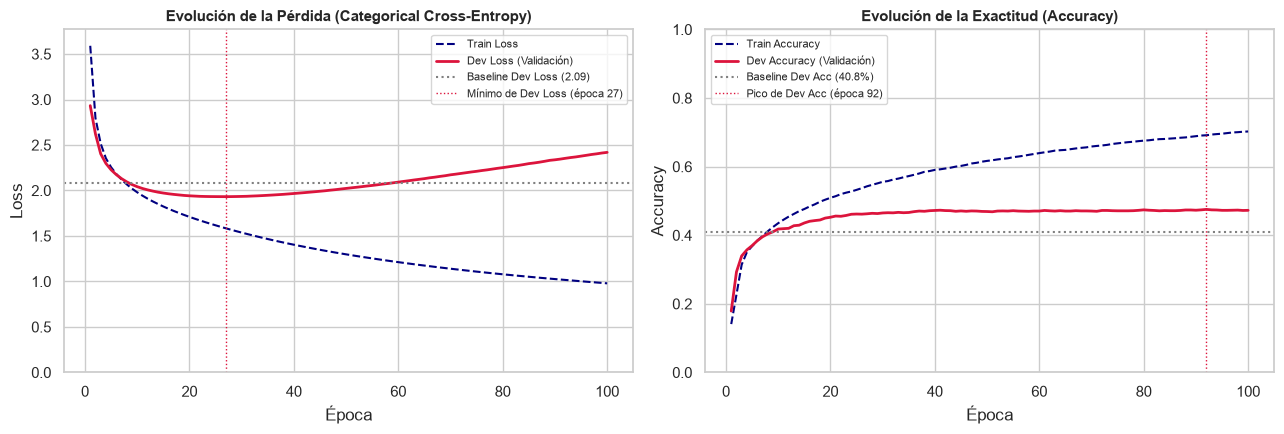

In [23]:
# ==============================================================================
# 7.2 CURVAS DE APRENDIZAJE DEL MLP SIN REGULARIZAR (Consigna 4.2.2)
# ==============================================================================
hist_mlp_base = historiales_lr[LR_OPT]
r_base = resultados_lr[LR_OPT]

print(f"MLP sin regularizar, lr = {LR_OPT:g}, {EPOCAS} épocas (5 semillas):")
print(f"  • Accuracy Train: {r_base['train_acc_mean']*100:.2f}% ± {r_base['train_acc_std']*100:.2f}%")
print(f"  • Accuracy Dev:   {r_base['dev_acc_mean']*100:.2f}% ± {r_base['dev_acc_std']*100:.2f}%")
print(f"  • Brecha Train - Dev: {r_base['brecha_mean']*100:.2f} pp")

epocas = range(1, len(hist_mlp_base["loss"]) + 1)
ep_min = int(np.argmin(hist_mlp_base["val_loss"])) + 1
ep_pico = int(np.argmax(hist_mlp_base["val_accuracy"])) + 1

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Curva de Pérdida (Loss)
axes[0].plot(epocas, hist_mlp_base["loss"], label="Train Loss", color="navy", linestyle="--")
axes[0].plot(epocas, hist_mlp_base["val_loss"], label="Dev Loss (Validación)", color="crimson", linewidth=2)
axes[0].axhline(loss_base_dev, color="gray", linestyle=":", label=f"Baseline Dev Loss ({loss_base_dev:.2f})")
axes[0].axvline(ep_min, color="crimson", linestyle=":", lw=1, label=f"Mínimo de Dev Loss (época {ep_min})")
axes[0].set_ylim(0, max(hist_mlp_base["loss"] + hist_mlp_base["val_loss"]) * 1.05)
axes[0].set_title("Evolución de la Pérdida (Categorical Cross-Entropy)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].legend(fontsize=8)

# Curva de Exactitud (Accuracy)
axes[1].plot(epocas, hist_mlp_base["accuracy"], label="Train Accuracy", color="navy", linestyle="--")
axes[1].plot(epocas, hist_mlp_base["val_accuracy"], label="Dev Accuracy (Validación)", color="crimson", linewidth=2)
axes[1].axhline(acc_base_dev, color="gray", linestyle=":", label=f"Baseline Dev Acc ({acc_base_dev*100:.1f}%)")
axes[1].axvline(ep_pico, color="crimson", linestyle=":", lw=1, label=f"Pico de Dev Acc (época {ep_pico})")
axes[1].set_ylim(0, 1)
axes[1].set_title("Evolución de la Exactitud (Accuracy)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

### 7.3 Learning rate variable: ReduceLROnPlateau

,Acc en mín. val_loss (μ ± σ),Pico acc Dev,Época mín. val_loss,Época del pico,Distancia (épocas),Mín. val_loss,Loss Dev final,Brecha final
Esquema,,,,,,,,
Fijo (0.0005),45.75% ± 0.50%,47.56% ± 0.42%,26.4,63.8,37.4,1.9200,2.4070,24.17 pp
"Fijo (0.0001), 300 épocas",45.96% ± 0.31%,47.61% ± 0.55%,134.2,265.0,130.8,1.9249,2.0837,17.24 pp
Plateau suave,46.23% ± 0.43%,47.38% ± 0.41%,15.4,40.4,25.0,1.9167,1.9453,14.23 pp
Plateau agresivo,46.76% ± 0.66%,47.12% ± 0.33%,18.8,20.6,1.8,1.9066,1.9083,11.15 pp


  Plateau agresivo + Dropout 0.05: Dev 47.80% ± 0.57% | brecha 12.15 pp | perplejidad 6.57


  Plateau agresivo + Dropout 0.1: Dev 47.93% ± 0.41% | brecha 11.28 pp | perplejidad 6.53

Esquema para la sección 8: Fijo (0.0005) -> {'lr': 0.0005}


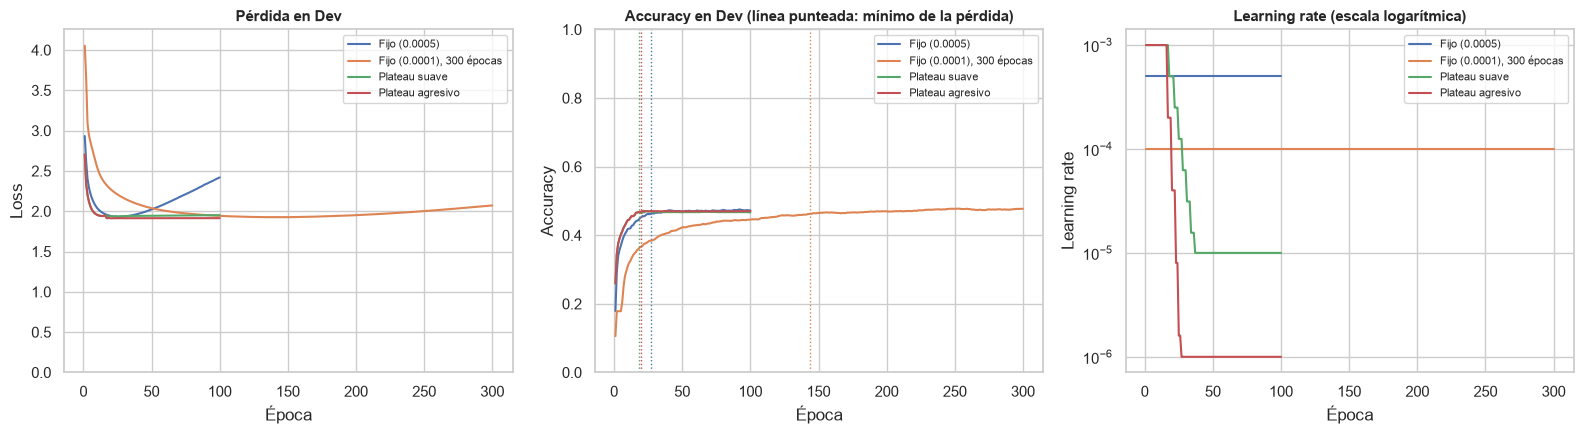

In [24]:
# ==============================================================================
# 7.3 LEARNING RATE FIJO VS REDUCELRONPLATEAU (MLP sin regularizar, 5 semillas)
# ==============================================================================
ESQUEMAS = {
    f"Fijo ({LR_OPT:g})": {"lr": LR_OPT},
    "Fijo (0.0001), 300 épocas": {"lr": 1e-4, "epochs": 300},
    "Plateau suave": {"lr": 1e-3, "plateau": {"factor": 0.5, "patience": 3, "min_lr": 1e-5}},
    "Plateau agresivo": {"lr": 1e-3, "plateau": {"factor": 0.2, "patience": 2, "min_lr": 1e-6}},
}

resultados_esq, historiales_esq, modelos_esq = {}, {}, {}
for nombre, cfg in ESQUEMAS.items():
    if cfg == {"lr": LR_OPT}:
        # El esquema fijo de la sección 7.1 ya está entrenado
        resultados_esq[nombre], historiales_esq[nombre], modelos_esq[nombre] = resultados_lr[LR_OPT], historiales_lr[LR_OPT], modelos_lr[LR_OPT]
    else:
        resultados_esq[nombre], historiales_esq[nombre], modelos_esq[nombre] = evaluar_config(cfg)

# Accuracy en la época del mínimo de val_loss, por semilla, a partir de lo guardado en las corridas
filas_esq = []
for nombre, r in resultados_esq.items():
    acc_min = [c["acc_en_min_loss"] for c in r["corridas"]]
    filas_esq.append({
        "Esquema": nombre,
        "Acc en mín. val_loss (μ ± σ)": f"{np.mean(acc_min)*100:.2f}% ± {np.std(acc_min, ddof=1)*100:.2f}%",
        "Pico acc Dev": f"{r['pico_acc_mean']*100:.2f}% ± {r['pico_acc_std']*100:.2f}%",
        "Época mín. val_loss": f"{r['ep_min_loss_mean']:.1f}",
        "Época del pico": f"{r['ep_pico_acc_mean']:.1f}",
        "Distancia (épocas)": f"{r['distancia_mean']:.1f}",
        "Mín. val_loss": f"{r['min_loss_mean']:.4f}",
        "Loss Dev final": f"{r['dev_loss_mean']:.4f}",
        "Brecha final": f"{r['brecha_mean']*100:.2f} pp",
    })
    r["acc_en_min_loss_mean"] = float(np.mean(acc_min))
display(pd.DataFrame(filas_esq).set_index("Esquema"))

# Comprobación: Dropout con Plateau agresivo, para comparar con la sección 8 (learning rate fijo)
plateau_dropout = {}
for d in [0.05, 0.1]:
    r, _, _ = evaluar_config({**ESQUEMAS["Plateau agresivo"], "dropout": d})
    plateau_dropout[d] = r
    print(f"  Plateau agresivo + Dropout {d:g}: Dev {r['dev_acc_mean']*100:.2f}% ± {r['dev_acc_std']*100:.2f}% | "
          f"brecha {r['brecha_mean']*100:.2f} pp | perplejidad {r['dev_perp_mean']:.2f}")

# Decisión (ver interpretación): la sección 8 sigue con el learning rate fijo de la sección 7.1
ESQUEMA = f"Fijo ({LR_OPT:g})"
CFG_ENTRENAMIENTO = ESQUEMAS[ESQUEMA]
print(f"\nEsquema para la sección 8: {ESQUEMA} -> {CFG_ENTRENAMIENTO}")

# Curvas de Dev de la semilla 42, marcando el mínimo de la pérdida
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for nombre, h in historiales_esq.items():
    ep = range(1, len(h["loss"]) + 1)
    e_min = int(np.argmin(h["val_loss"])) + 1
    l = axes[0].plot(ep, h["val_loss"], label=nombre)[0]
    axes[1].plot(ep, h["val_accuracy"], label=nombre, color=l.get_color())
    axes[1].axvline(e_min, color=l.get_color(), linestyle=":", lw=1)
    lrs = h["learning_rate"] if "learning_rate" in h else [ESQUEMAS[nombre]["lr"]] * len(ep)
    axes[2].plot(ep, lrs, label=nombre, color=l.get_color())
axes[0].set_ylim(0, max(max(h["val_loss"]) for h in historiales_esq.values()) * 1.05)
axes[1].set_ylim(0, 1)
axes[2].set_yscale("log")
axes[0].set_title("Pérdida en Dev", fontsize=11, fontweight="bold")
axes[1].set_title("Accuracy en Dev (línea punteada: mínimo de la pérdida)", fontsize=11, fontweight="bold")
axes[2].set_title("Learning rate (escala logarítmica)", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Loss")
axes[1].set_ylabel("Accuracy")
axes[2].set_ylabel("Learning rate")
for ax in axes:
    ax.set_xlabel("Época")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# 8. Consigna 4.2.3: Regularización
### Cómo las evaluamos
### Qué esperamos al combinarlas

### ¿Por qué sumamos Batch Normalization?

### 8.1 Cada técnica por separado

In [25]:
# ==============================================================================
# 8.1 CADA TÉCNICA DE REGULARIZACIÓN POR SEPARADO (5 semillas)
# ==============================================================================
GRILLA_IND = {
    "Dropout": [{"dropout": d} for d in [0.05, 0.1, 0.2, 0.3]],
    "L2": [{"l2": v} for v in [1e-6, 1e-5, 1e-4]],
    "Early Stopping": [{"use_es": True, "patience": p} for p in [5, 10, 20]],
    "Batch Normalization": [{"batchnorm": True}],
}

def nombre_config(cfg):
    """Nombre legible de una configuración de regularización."""
    partes = []
    if cfg.get("dropout"):
        partes.append(f"Dropout {cfg['dropout']:g}")
    if cfg.get("l2"):
        partes.append(f"L2 {cfg['l2']:g}")
    if cfg.get("batchnorm"):
        partes.append("BatchNorm")
    if cfg.get("use_es"):
        partes.append(f"ES (paciencia {cfg['patience']})")
    return " + ".join(partes) if partes else "MLP Base"

# El MLP Base es el MLP sin regularizar con el learning rate fijo de la sección 7.1
resultados_ablacion = {"MLP Base": resultados_esq[ESQUEMA]}
historiales_seed42  = {"MLP Base": historiales_esq[ESQUEMA]}
modelos_seed42      = {"MLP Base": modelos_esq[ESQUEMA]}

def correr(cfg):
    """Entrena la configuración (si no se entrenó antes) y devuelve su nombre."""
    nombre = nombre_config(cfg)
    if nombre not in resultados_ablacion:
        resultados_ablacion[nombre], historiales_seed42[nombre], modelos_seed42[nombre] = evaluar_config({**CFG_ENTRENAMIENTO, **cfg})
    return nombre

def fila_resumen(nombre, **extra):
    r, base = resultados_ablacion[nombre], resultados_ablacion["MLP Base"]
    return {**extra, "Configuración": nombre,
            "Dev Acc (μ ± σ)": f"{r['dev_acc_mean']*100:.2f}% ± {r['dev_acc_std']*100:.2f}%",
            "Peor semilla": f"{r['dev_acc_min']*100:.2f}%",
            "Δ vs MLP Base": f"{(r['dev_acc_mean'] - base['dev_acc_mean'])*100:+.2f} pp",
            "Train Acc": f"{r['train_acc_mean']*100:.2f}%",
            "Brecha": f"{r['brecha_mean']*100:.2f} pp",
            "Dev Loss": f"{r['dev_loss_mean']:.4f}",
            "Perplejidad": f"{r['dev_perp_mean']:.2f}",
            "Épocas": f"{r['epocas_mean']:.1f}"}

MEJOR_POR_TECNICA = {}
filas_ind = [fila_resumen("MLP Base", Técnica="Ninguna")]

for tecnica, cfgs in GRILLA_IND.items():
    nombres = [correr(c) for c in cfgs]
    filas_ind += [fila_resumen(n, Técnica=tecnica) for n in nombres]
    i_mejor = max(range(len(cfgs)), key=lambda i: resultados_ablacion[nombres[i]]["dev_acc_mean"])
    MEJOR_POR_TECNICA[tecnica] = cfgs[i_mejor]
    borde = len(cfgs) > 1 and i_mejor in (0, len(cfgs) - 1)
    print(f"  {tecnica:<20} mejor: {nombres[i_mejor]:<22} | ¿En el borde del rango? {borde}")

display(pd.DataFrame(filas_ind).set_index(["Técnica", "Configuración"]))

  Dropout              mejor: Dropout 0.05           | ¿En el borde del rango? True


  L2                   mejor: L2 0.0001              | ¿En el borde del rango? True


  Early Stopping       mejor: ES (paciencia 5)       | ¿En el borde del rango? True


  Batch Normalization  mejor: BatchNorm              | ¿En el borde del rango? False


Dev Acc (μ ± σ) Peor semilla  \
Técnica             Configuración                                    
Ninguna             MLP Base           46.90% ± 0.49%       46.42%   
Dropout             Dropout 0.05       48.71% ± 0.52%       48.16%   
                    Dropout 0.1        48.61% ± 0.40%       48.12%   
                    Dropout 0.2        48.14% ± 0.73%       47.15%   
                    Dropout 0.3        46.90% ± 0.38%       46.42%   
L2                  L2 1e-06           46.66% ± 0.49%       45.97%   
                    L2 1e-05           46.72% ± 0.49%       46.11%   
                    L2 0.0001          47.08% ± 0.35%       46.77%   
Early Stopping      ES (paciencia 5)   45.75% ± 0.50%       45.14%   
                    ES (paciencia 10)  45.75% ± 0.50%       45.14%   
                    ES (paciencia 20)  45.75% ± 0.50%       45.14%   
Batch Normalization BatchNorm          43.10% ± 0.71%       42.22%   

                                      Δ vs MLP Base Train Acc    Brecha  \
Técnica             Configuración                                         
Ninguna             MLP Base               +0.00 pp    71.07%  24.17 pp   
Dropout             Dropout 0.05           +1.81 pp    69.43%  20.72 pp   
                    Dropout 0.1            +1.71 pp    66.63%  18.01 pp   
                    Dropout 0.2            +1.24 pp    61.60%  13.46 pp   
                    Dropout 0.3            -0.01 pp    57.04%  10.15 pp   
L2                  L2 1e-06               -0.24 pp    70.66%  24.00 pp   
                    L2 1e-05               -0.19 pp    70.72%  24.01 pp   
                    L2 0.0001              +0.18 pp    69.75%  22.67 pp   
Early Stopping      ES (paciencia 5)       -1.15 pp    54.94%   9.19 pp   
                    ES (paciencia 10)      -1.15 pp    54.94%   9.19 pp   
                    ES (paciencia 20)      -1.15 pp    54.94%   9.19 pp   
Batch Normalization BatchNorm              -3.80 pp    73.91%  30.81 pp   

                                      Dev Loss Perplejidad Épocas  
Técnica             Configuración                                  
Ninguna             MLP Base            2.4070       11.11  100.0  
Dropout             Dropout 0.05        2.0363        7.66  100.0  
                    Dropout 0.1         1.9557        7.07  100.0  
                    Dropout 0.2         1.9097        6.75  100.0  
                    Dropout 0.3         1.9226        6.84  100.0  
L2                  L2 1e-06            2.4076       11.11  100.0  
                    L2 1e-05            2.3952       10.98  100.0  
                    L2 0.0001           2.4049       11.08  100.0  
Early Stopping      ES (paciencia 5)    1.9200        6.82   31.4  
                    ES (paciencia 10)   1.9200        6.82   36.4  
                    ES (paciencia 20)   1.9200        6.82   46.4  
Batch Normalization BatchNorm           5.5251      252.28  100.0

### 8.2 Combinación incremental

In [26]:
# ==============================================================================
# 8.2 COMBINACIÓN INCREMENTAL DE TÉCNICAS (Consigna 4.2.3)
# ==============================================================================
actual_cfg, actual = {}, "MLP Base"
restantes = list(GRILLA_IND)
pasos = []
paso = 1

while restantes:
    candidatos = [(t, {**actual_cfg, **MEJOR_POR_TECNICA[t]}) for t in restantes]
    candidatos = [(t, cfg, correr(cfg)) for t, cfg in candidatos]
    t_mejor, cfg_mejor, n_mejor = max(candidatos, key=lambda c: resultados_ablacion[c[2]]["dev_acc_mean"])

    umbral = resultados_ablacion[actual]["dev_acc_std"]
    ganancia = resultados_ablacion[n_mejor]["dev_acc_mean"] - resultados_ablacion[actual]["dev_acc_mean"]
    acepta = ganancia > umbral

    for t, cfg, n in candidatos:
        g = resultados_ablacion[n]["dev_acc_mean"] - resultados_ablacion[actual]["dev_acc_mean"]
        pasos.append({"Paso": paso, "Modelo actual": actual, "Se agrega": t, "Candidato": n,
                      "Dev Acc (μ ± σ)": f"{resultados_ablacion[n]['dev_acc_mean']*100:.2f}% ± {resultados_ablacion[n]['dev_acc_std']*100:.2f}%",
                      "Ganancia": f"{g*100:+.2f} pp", "Umbral": f"{umbral*100:.2f} pp",
                      "¿Se acepta?": "Sí" if (n == n_mejor and acepta) else "No"})
    if not acepta:
        break
    actual_cfg, actual = cfg_mejor, n_mejor
    restantes.remove(t_mejor)
    paso += 1

GANADOR = actual
display(pd.DataFrame(pasos).set_index(["Paso", "Candidato"]))
print(f"\nModelo ganador de la Etapa 2: {GANADOR}")

# Persistencia oficial en disco para la Etapa 5
registro_etapa2 = {
    "baseline": {
        "params": params_base, "tiempo": tiempo_base,
        "train_acc": float(acc_base_train), "dev_acc": float(acc_base_dev),
        "brecha": float(acc_base_train - acc_base_dev),
        "dev_loss": loss_base_dev, "dev_perp": perp_base_dev
    },
    "learning_rate": {"valores": LRS, "elegido": LR_OPT, "epocas": EPOCAS,
                      "resultados": {f"{lr:g}": r for lr, r in resultados_lr.items()}},
    "esquema_lr": {"esquemas": ESQUEMAS, "elegido": ESQUEMA, "config": CFG_ENTRENAMIENTO,
                   "acc_en_min_loss": {n: r["acc_en_min_loss_mean"] for n, r in resultados_esq.items()},
                   "plateau_con_dropout": {f"{d:g}": r for d, r in plateau_dropout.items()}},
    "mejor_por_tecnica": MEJOR_POR_TECNICA,
    "pasos_incrementales": pasos,
    "configuraciones": resultados_ablacion,
    "ganador": GANADOR
}
with open(os.path.join("..", "data", "processed", "resultados_modelos.json"), "w", encoding="utf-8") as f:
    json.dump(registro_etapa2, f, indent=2, default=float, ensure_ascii=False)

print("Resultados persistidos en data/processed/resultados_modelos.json")

Modelo actual            Se agrega  \
Paso Candidato                                                            
1    Dropout 0.05                         MLP Base              Dropout   
     L2 0.0001                            MLP Base                   L2   
     ES (paciencia 5)                     MLP Base       Early Stopping   
     BatchNorm                            MLP Base  Batch Normalization   
2    Dropout 0.05 + L2 0.0001         Dropout 0.05                   L2   
     Dropout 0.05 + ES (paciencia 5)  Dropout 0.05       Early Stopping   
     Dropout 0.05 + BatchNorm         Dropout 0.05  Batch Normalization   

                                     Dev Acc (μ ± σ)  Ganancia   Umbral  \
Paso Candidato                                                            
1    Dropout 0.05                     48.71% ± 0.52%  +1.81 pp  0.49 pp   
     L2 0.0001                        47.08% ± 0.35%  +0.18 pp  0.49 pp   
     ES (paciencia 5)                 45.75% ± 0.50%  -1.15 pp  0.49 pp   
     BatchNorm                        43.10% ± 0.71%  -3.80 pp  0.49 pp   
2    Dropout 0.05 + L2 0.0001         48.70% ± 0.55%  -0.01 pp  0.52 pp   
     Dropout 0.05 + ES (paciencia 5)  47.00% ± 0.49%  -1.71 pp  0.52 pp   
     Dropout 0.05 + BatchNorm         48.32% ± 0.47%  -0.39 pp  0.52 pp   

                                     ¿Se acepta?  
Paso Candidato                                    
1    Dropout 0.05                             Sí  
     L2 0.0001                                No  
     ES (paciencia 5)                         No  
     BatchNorm                                No  
2    Dropout 0.05 + L2 0.0001                 No  
     Dropout 0.05 + ES (paciencia 5)          No  
     Dropout 0.05 + BatchNorm                 No


Modelo ganador de la Etapa 2: Dropout 0.05
Resultados persistidos en data/processed/resultados_modelos.json


TABLA COMPARATIVA DE MODELOS - ETAPA 2 (esquema de learning rate: Fijo (0.0005); evaluación en Dev con 5 semillas; ★ = ganador)



,Parámetros,Tiempo Train (s),Train Accuracy,Dev Accuracy (μ ± σ),Dev Accuracy (peor semilla),Brecha Train-Dev,Dev Loss,Dev Perplejidad
Modelo,,,,,,,,
Baseline K=5 (Logística),"19,908",1.69,42.97%,40.83%,—,2.13 pp,2.0853,8.05
MLP Base,"53,536",23.30,71.07%,46.90% ± 0.49%,46.42%,24.17 pp,2.4070,11.11
Dropout 0.05 ★,"53,536",26.72,69.43%,48.71% ± 0.52%,48.16%,20.72 pp,2.0363,7.66
L2 0.0001,"53,536",21.86,69.75%,47.08% ± 0.35%,46.77%,22.67 pp,2.4049,11.08
ES (paciencia 5),"53,536",7.27,54.94%,45.75% ± 0.50%,45.14%,9.19 pp,1.9200,6.82
BatchNorm,"54,432",26.19,73.91%,43.10% ± 0.71%,42.22%,30.81 pp,5.5251,252.28
Dropout 0.05 + L2 0.0001,"53,536",24.54,68.32%,48.70% ± 0.55%,48.16%,19.62 pp,2.0890,8.08
Dropout 0.05 + ES (paciencia 5),"53,536",10.67,57.57%,47.00% ± 0.49%,46.42%,10.57 pp,1.8825,6.57
Dropout 0.05 + BatchNorm,"54,432",29.18,77.05%,48.32% ± 0.47%,47.50%,28.73 pp,2.3907,10.92


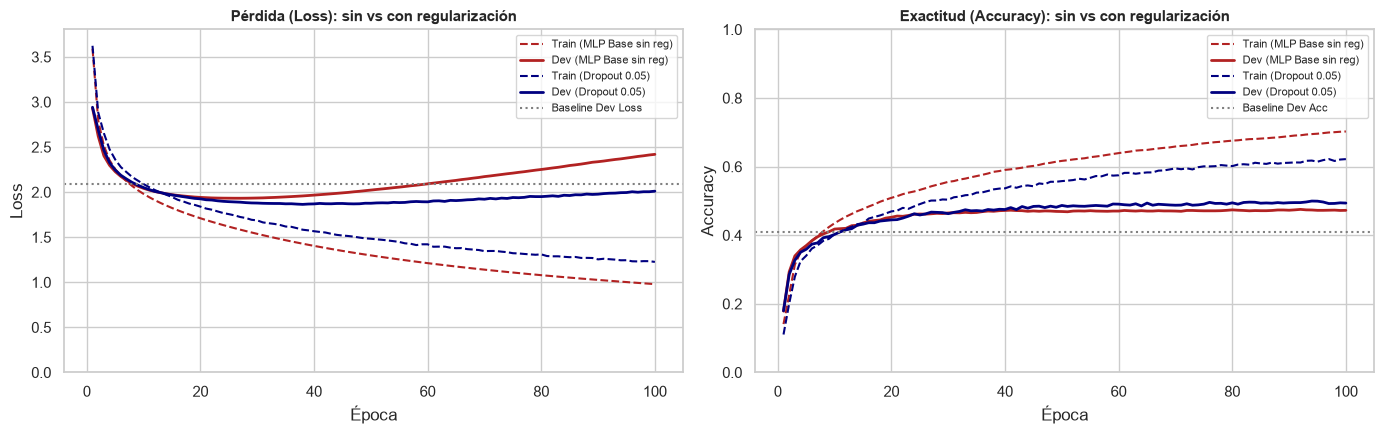

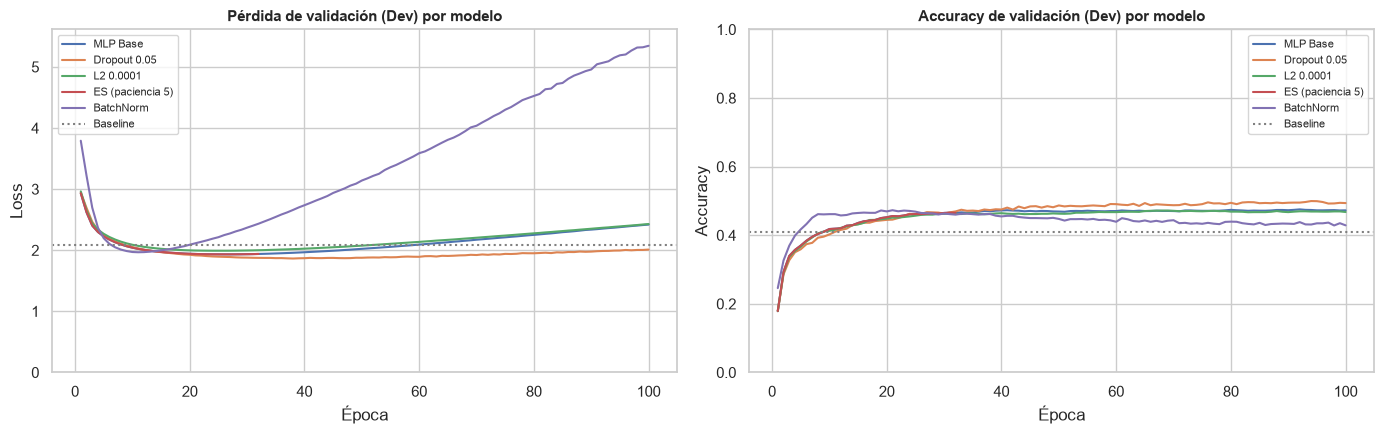

In [27]:
# ==============================================================================
# 8.3 TABLA SÍNTESIS Y CURVAS COMPARATIVAS (Consigna 4.2.3)
# ==============================================================================
mejores_ind = [nombre_config(c) for c in MEJOR_POR_TECNICA.values()]
combinados = [p["Candidato"] for p in pasos if p["Candidato"] not in mejores_ind]
en_tabla = list(dict.fromkeys(["MLP Base"] + mejores_ind + combinados))

filas_tabla = [{
    "Modelo": "Baseline K=5 (Logística)",
    "Parámetros": f"{params_base:,}",
    "Tiempo Train (s)": f"{tiempo_base:.2f}",
    "Train Accuracy": f"{acc_base_train*100:.2f}%",
    "Dev Accuracy (μ ± σ)": f"{acc_base_dev*100:.2f}%",
    "Dev Accuracy (peor semilla)": "—",
    "Brecha Train-Dev": f"{(acc_base_train - acc_base_dev)*100:.2f} pp",
    "Dev Loss": f"{loss_base_dev:.4f}",
    "Dev Perplejidad": f"{perp_base_dev:.2f}"
}]
for n in en_tabla:
    v_m = resultados_ablacion[n]
    filas_tabla.append({
        "Modelo": n + (" ★" if n == GANADOR else ""),
        "Parámetros": f"{v_m['params']:,}",
        "Tiempo Train (s)": f"{v_m['tiempo_mean']:.2f}",
        "Train Accuracy": f"{v_m['train_acc_mean']*100:.2f}%",
        "Dev Accuracy (μ ± σ)": f"{v_m['dev_acc_mean']*100:.2f}% ± {v_m['dev_acc_std']*100:.2f}%",
        "Dev Accuracy (peor semilla)": f"{v_m['dev_acc_min']*100:.2f}%",
        "Brecha Train-Dev": f"{v_m['brecha_mean']*100:.2f} pp",
        "Dev Loss": f"{v_m['dev_loss_mean']:.4f}",
        "Dev Perplejidad": f"{v_m['dev_perp_mean']:.2f}"
    })

df_sintesis = pd.DataFrame(filas_tabla).set_index("Modelo")
print(f"TABLA COMPARATIVA DE MODELOS - ETAPA 2 (esquema de learning rate: {ESQUEMA}; evaluación en Dev con 5 semillas; ★ = ganador)\n")
display(df_sintesis)

# Figura 1: con vs sin regularización, Train y Dev (semilla 42)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
h_base = historiales_seed42["MLP Base"]
h_opt  = historiales_seed42[GANADOR]
ep_b = range(1, len(h_base["loss"]) + 1)
ep_o = range(1, len(h_opt["loss"]) + 1)

axes[0].plot(ep_b, h_base["loss"], label="Train (MLP Base sin reg)", color="firebrick", linestyle="--")
axes[0].plot(ep_b, h_base["val_loss"], label="Dev (MLP Base sin reg)", color="firebrick", linewidth=2)
axes[0].plot(ep_o, h_opt["loss"], label=f"Train ({GANADOR})", color="navy", linestyle="--")
axes[0].plot(ep_o, h_opt["val_loss"], label=f"Dev ({GANADOR})", color="navy", linewidth=2)
axes[0].axhline(loss_base_dev, color="gray", linestyle=":", label="Baseline Dev Loss")
axes[0].set_ylim(0, max(h_base["loss"] + h_base["val_loss"] + h_opt["loss"] + h_opt["val_loss"]) * 1.05)
axes[0].set_title("Pérdida (Loss): sin vs con regularización", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Loss")

axes[1].plot(ep_b, h_base["accuracy"], label="Train (MLP Base sin reg)", color="firebrick", linestyle="--")
axes[1].plot(ep_b, h_base["val_accuracy"], label="Dev (MLP Base sin reg)", color="firebrick", linewidth=2)
axes[1].plot(ep_o, h_opt["accuracy"], label=f"Train ({GANADOR})", color="navy", linestyle="--")
axes[1].plot(ep_o, h_opt["val_accuracy"], label=f"Dev ({GANADOR})", color="navy", linewidth=2)
axes[1].axhline(acc_base_dev, color="gray", linestyle=":", label="Baseline Dev Acc")
axes[1].set_ylim(0, 1)
axes[1].set_title("Exactitud (Accuracy): sin vs con regularización", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Accuracy")
for ax in axes:
    ax.set_xlabel("Época")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Figura 2: curvas de validación del MLP Base, la mejor versión de cada técnica y el ganador
a_graficar = list(dict.fromkeys(["MLP Base"] + mejores_ind + [GANADOR]))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for nombre in a_graficar:
    hist = historiales_seed42[nombre]
    ep = range(1, len(hist["loss"]) + 1)
    axes[0].plot(ep, hist["val_loss"], label=nombre)
    axes[1].plot(ep, hist["val_accuracy"], label=nombre)
axes[0].axhline(loss_base_dev, color="gray", linestyle=":", label="Baseline")
axes[1].axhline(acc_base_dev, color="gray", linestyle=":", label="Baseline")
axes[0].set_ylim(0, max(max(historiales_seed42[n]["val_loss"]) for n in a_graficar) * 1.05)
axes[1].set_ylim(0, 1)
axes[0].set_title("Pérdida de validación (Dev) por modelo", fontsize=11, fontweight="bold")
axes[1].set_title("Accuracy de validación (Dev) por modelo", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Loss")
axes[1].set_ylabel("Accuracy")
for ax in axes:
    ax.set_xlabel("Época")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 8.4 ¿Dónde mejora el MLP?

,Casos en Dev,% de Dev,Accuracy Baseline,Accuracy Dropout 0.05,Δ (pp)
espacio,514,17.8,0.8580,0.8930,3.50
vocal,817,28.4,0.3060,0.4223,11.63
consonante,1451,50.4,0.3280,0.4197,9.17
mayúscula,38,1.3,0.1842,0.1579,-2.63
puntuación/dígito,60,2.1,0.0333,0.0500,1.67


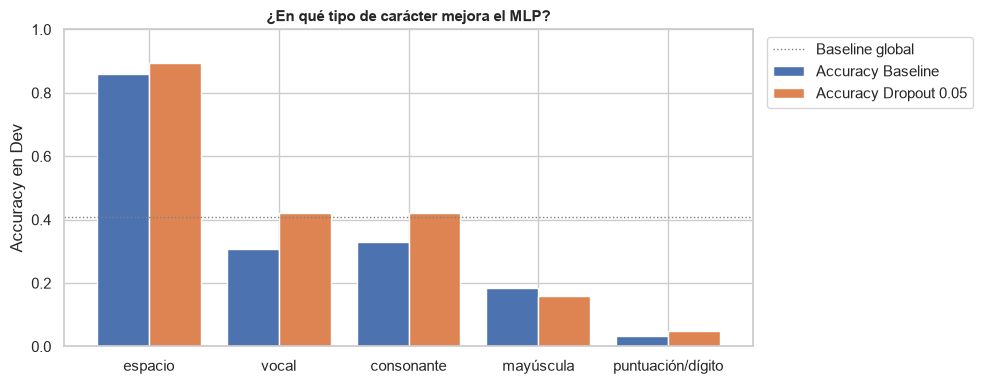

Causa (pre-etiqueta por reglas): Falta de cobertura (5-grama nuevo)
  [Baseline] contexto '...ad been striking. Af' | real 't' en el puesto 4 (P = 0.074)
     top-5: '<SP>' 0.503 | 'a' 0.102 | 'o' 0.100 | 't' 0.074 | 'l' 0.048
  [Dropout 0.05] contexto '...ad been striking. Af' | real 't' en el puesto 1 (P = 0.922)
     top-5: 't' 0.922 | 'f' 0.056 | 'a' 0.011 | 'h' 0.003 | '<SP>' 0.002

Causa (pre-etiqueta por reglas): Ruido irreducible (Error Bayes)
  [Baseline] contexto '... wrote a quaint and ' | real 'a' en el puesto 4 (P = 0.090)
     top-5: 't' 0.147 | 'w' 0.140 | 's' 0.095 | 'a' 0.090 | 'h' 0.059
  [Dropout 0.05] contexto '... wrote a quaint and ' | real 'a' en el puesto 5 (P = 0.054)
     top-5: 't' 0.205 | 's' 0.140 | 'w' 0.117 | 'm' 0.057 | 'a' 0.054

Causa (pre-etiqueta por reglas): Sesgo (Underfitting)
  [Baseline] contexto '...tone above with a na' | real 's' en el puesto 3 (P = 0.088)
     top-5: 't' 0.160 | 'd' 0.127 | 's' 0.088 | 'l' 0.087 | '<SP>' 0.086
  [Dropout 0.0

  [Dropout 0.05] contexto '...ersons on the settle' | real ',' en el puesto 2 (P = 0.043)
     top-5: '<SP>' 0.905 | ',' 0.043 | 's' 0.012 | '.' 0.010 | '-' 0.007



In [28]:
# ==============================================================================
# 8.4 BASELINE VS MODELO GANADOR: ACCURACY POR TIPO Y EXPLICACIÓN DE CASOS
# ==============================================================================
modelo_ganador = modelos_seed42[GANADOR]

def proba_mlp(contextos, modelo=modelo_ganador):
    """Matriz (n, |V|) de probabilidades del MLP, en el orden de char2idx."""
    X_oh, _ = extraer_tensores_onehot(contextos, [" "] * len(contextos), K_OPTIMO, char2idx, vocab_size)
    return modelo.predict(X_oh, verbose=0)

y_pred_dev_mlp = [idx2char[i] for i in proba_mlp(X_dev).argmax(axis=1)]

df_tipos = df_tipos_base.copy()
df_tipos[f"Accuracy {GANADOR}"] = pd.Series(accuracy_por_tipo(y_pred_dev_mlp)).reindex(TIPOS_CHAR).round(4)
df_tipos["Δ (pp)"] = ((df_tipos[f"Accuracy {GANADOR}"] - df_tipos["Accuracy Baseline"]) * 100).round(2)
display(df_tipos)

# Gráfico de barras agrupadas por tipo
ax = df_tipos[["Accuracy Baseline", f"Accuracy {GANADOR}"]].plot.bar(figsize=(10, 4), width=0.8, rot=0)
ax.axhline(acc_base_dev, color="gray", ls=":", lw=1, label="Baseline global")
ax.set_ylim(0, 1)
ax.set_ylabel("Accuracy en Dev")
ax.set_xlabel("")
ax.set_title("¿En qué tipo de carácter mejora el MLP?", fontsize=11, fontweight="bold")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

# Mismos casos de la sección 6.4, ahora con ambos modelos
for _, fila in casos_ejemplo.iterrows():
    print(f"Causa (pre-etiqueta por reglas): {fila['causa_teorica']}")
    explicar_prediccion(proba_baseline, X_dev[fila["dev_idx"]], fila["y_real"], "Baseline")
    explicar_prediccion(proba_mlp, X_dev[fila["dev_idx"]], fila["y_real"], GANADOR)
    print()


In [29]:
# ==============================================================================
# 8.5 ESTIMACIÓN DEL SESGO EVITABLE DEL BASELINE (ver advertencia de la sección 6.2)
# ==============================================================================
err_tr_base    = 1 - acc_base_train
err_tr_mlpbase = 1 - resultados_ablacion["MLP Base"]["train_acc_mean"]
err_tr_ganador = 1 - resultados_ablacion[GANADOR]["train_acc_mean"]
mejora_dev     = resultados_ablacion[GANADOR]["dev_acc_mean"] - acc_base_dev

print(f"Error de Train del baseline:                 {err_tr_base*100:.2f}%")
print(f"Error de Train del MLP sin regularizar:      {err_tr_mlpbase*100:.2f}%  (memoriza: no sirve como cota)")
print(f"Error de Train del modelo ganador:           {err_tr_ganador*100:.2f}%")
print(f"\nReducción del error de Train con el ganador: {(err_tr_base - err_tr_ganador)*100:.2f} pp")
print(f"Mejora en Dev del ganador sobre el baseline: {mejora_dev*100:.2f} pp")

Error de Train del baseline:                 57.03%
Error de Train del MLP sin regularizar:      28.93%  (memoriza: no sirve como cota)
Error de Train del modelo ganador:           30.57%

Reducción del error de Train con el ganador: 26.46 pp
Mejora en Dev del ganador sobre el baseline: 7.88 pp


### 8.6 Conclusiones de la Etapa 2

### 8.7 Registro de experimentos que no funcionaron

# 9. Síntesis y checklist de la Etapa 2

In [30]:
# ==============================================================================
# 9.1 CHECKLIST OFICIAL DE CUMPLIMIENTO - ETAPA 2 (UNAB 2026)
# ==============================================================================
r_gan = resultados_ablacion[GANADOR]
delta_gan = (r_gan["dev_acc_mean"] - acc_base_dev) * 100

print("=" * 80)
print("CHECKLIST DE CUMPLIMIENTO - ETAPA 2 (UNAB 2026)")
print("=" * 80)
print(f"  [ ] 4.2.1 Análisis de errores manual: 50 muestras pre-etiquetadas por reglas; falta la revisión manual.")
print(f"  [x] 4.2.1 Diagnóstico de sesgo vs varianza del baseline (brecha Train - Dev = {(acc_base_train - acc_base_dev)*100:.2f} pp).")
print(f"  [x] 4.2.1 Accuracy por tipo de carácter y explicación de predicciones.")
print(f"  [x] 4.2.2 Arquitectura MLP en tf.keras: 3 capas ocultas (128-64-32, {resultados_ablacion['MLP Base']['params']:,} parámetros).")
print(f"  [x] 4.2.2 Funciones documentadas: ReLU, Softmax, Loss Categorical Cross-Entropy y Adam (lr fijo = {LR_OPT:g}, sección 7.1; ReduceLROnPlateau evaluado en la 7.3).")
print(f"  [x] 4.2.2 Curvas de aprendizaje (Loss y Accuracy) en Train y Dev.")
print(f"  [x] 4.2.3 Regularización: 4 técnicas probadas de a una (mejores: {', '.join(mejores_ind)}).")
print(f"  [x] 4.2.3 Combinación incremental con 5 semillas por configuración, curvas con y sin regularización.")
print(f"  [x] 4.2.3 Mejora sobre el Baseline en Dev: {GANADOR} = {r_gan['dev_acc_mean']*100:.2f}% ± {r_gan['dev_acc_std']*100:.2f}% ({delta_gan:+.2f} pp).")
print(f"  [x] Parámetros y tiempos registrados en resultados_modelos.json para la Etapa 5.")
print(f"  [x] Conjunto Test estrictamente preservado sin evaluar hasta la Etapa 5.")
print("=" * 80)

CHECKLIST DE CUMPLIMIENTO - ETAPA 2 (UNAB 2026)
  [ ] 4.2.1 Análisis de errores manual: 50 muestras pre-etiquetadas por reglas; falta la revisión manual.
  [x] 4.2.1 Diagnóstico de sesgo vs varianza del baseline (brecha Train - Dev = 2.13 pp).
  [x] 4.2.1 Accuracy por tipo de carácter y explicación de predicciones.
  [x] 4.2.2 Arquitectura MLP en tf.keras: 3 capas ocultas (128-64-32, 53,536 parámetros).
  [x] 4.2.2 Funciones documentadas: ReLU, Softmax, Loss Categorical Cross-Entropy y Adam (lr fijo = 0.0005, sección 7.1; ReduceLROnPlateau evaluado en la 7.3).
  [x] 4.2.2 Curvas de aprendizaje (Loss y Accuracy) en Train y Dev.
  [x] 4.2.3 Regularización: 4 técnicas probadas de a una (mejores: Dropout 0.05, L2 0.0001, ES (paciencia 5), BatchNorm).
  [x] 4.2.3 Combinación incremental con 5 semillas por configuración, curvas con y sin regularización.
  [x] 4.2.3 Mejora sobre el Baseline en Dev: Dropout 0.05 = 48.71% ± 0.52% (+7.88 pp).
  [x] Parámetros y tiempos registrados en resultados_